# MODEL_POISSON — Prédire le score d'un match de Ligue des Champions

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — partie modèle : Moussa

> **Nous prédisons le score d'un match de Ligue des Champions avant le coup d'envoi, pour estimer la probabilité de titre de chaque club en 2026-2027.**

## Objectif
Prédire **le score** d'un match de C1 avant le coup d'envoi, pas seulement son vainqueur. La simulation de la saison 2026-2027 a besoin de scores pour deux règles de l'UEFA :
- en **phase de ligue**, les égalités de points se départagent à la **différence de buts**, puis aux buts marqués ;
- en **phase finale**, les matchs aller-retour se jouent sur le **score cumulé**.

## Résumé
- **Le modèle final atteint 60,4 % d'accuracy sur le test 2023-2025** (303 matchs bien prédits sur 502), contre **58,6 %** pour le modèle Elo + terrain et **50,0 %** pour le Dummy. Sur la saison 2025-2026, jamais vue, il fait **60,1 %**.
- **Ce gain vient de deux informations nouvelles** (section 10, `v2_forces.ipynb`) : une **force d'attaque et une force de défense** par club, apprises sur environ 18 000 matchs de clubs, et la **valeur des joueurs utilisés récemment**, une approximation des blessures. Il est **significatif** sur la log loss : 0,8925 contre 0,9023 sur le test, avec un intervalle de +0,002 à +0,018.
- **Le modèle de départ, Elo + terrain** (sections 2 à 9), est déjà aussi bon que la logistique ordinale : log loss de 0,902 contre 0,904, et 58,6 % d'accuracy. Il donne en plus des scores crédibles, et répond à la question de l'atelier, « victoire à domicile oui/non », dans **68,1 %** des cas.
- **Il fait jeu égal avec les bookmakers** (section 10 bis) : sur les mêmes 502 matchs de test, Pinnacle, le bookmaker de référence, fait **60,2 %**, et notre modèle **60,4 %**. Même en mélangeant notre modèle avec leurs cotes, on ne fait pas mieux : **60 % est le plafond** sur ces saisons.
- **Depuis le nouveau format, on observe plus de buts** : +13 % depuis 2024. Le modèle final en tient compte.
- **Les pistes du prof** (Dixon-Coles, blend, Poisson bivarié, fine-tuning) et la forme récente ne font pas mieux. Le Poisson bivarié confirme même que les buts des deux équipes sont indépendants une fois le niveau connu.
- **Livrables :** `output/modele_scores.joblib` et les prédictions des 144 matchs de la phase de ligue 2026-2027.

## Le cadre
| Élément | Choix |
|---|---|
| Une ligne | un match de C1, 1 871 matchs de 2012-2013 à 2025-2026 |
| Ce qu'on prédit | les buts de chaque équipe, d'où l'on tire les probabilités de chaque score, puis de victoire, nul et défaite |
| Variables | l'**écart d'Elo complet**, le **terrain** (domicile, extérieur ou neutre) et le **format** de la compétition (ancien, ou nouveau depuis 2024) ; puis, en section 10, les **forces d'attaque et de défense** et la **valeur des joueurs récents** (`v2_forces.ipynb`) : tout est connu avant le match |
| Type de problème | **régression de comptage** (des buts), d'où l'on tire une **classification** (victoire, nul, défaite) |
| Modèle | régression de Poisson dans un `Pipeline` scikit-learn (`SimpleImputer` + `PoissonRegressor`) |
| Split | **chronologique** : validation glissante sur 8 saisons (2015 à 2022), test sur **2023 à 2025** |
| Baselines | `DummyClassifier` (fréquences passées), `DummyRegressor` (buts moyens), et la logistique ordinale de `MODEL_BASELINE` (mêmes variables) |
| Métriques | **log loss** (critère de choix : la simulation utilise des probabilités), RPS, accuracy, **balanced accuracy**, **matrice de confusion**, **MAE des buts** |
| Livrable | `output/modele_scores.joblib` et `output/predictions_phase_ligue_2026.csv` |

## Plan
1. Les données et leurs contrôles
2. Le modèle, dans un Pipeline
3. Des buts aux probabilités
4. Validation glissante sur 8 saisons
5. Test final sur 2023-2025
6. Les scores prédits sont-ils réalistes ?
7. Depuis le nouveau format, on observe plus de buts
8. La forme récente apporte-t-elle quelque chose ?
9. Les pistes du prof : Dixon-Coles, blend, Poisson bivarié, fine-tuning
10. De nouvelles informations : forces d'attaque et de défense, joueurs récents ; face aux bookmakers
11. Le modèle final et ce qu'il a appris
12. Export pour l'application et la simulation
13. Prédictions de la phase de ligue 2026-2027
14. Conclusion

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from math import factorial
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, mean_absolute_error

%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, VERT, GRIS, ENCRE = '#2a78d6', '#eb6834', '#1baf7a', '#b5b3ad', '#52514e'
ISSUES = ['Victoire domicile', 'Nul', 'Victoire extérieur']   # ordre naturel : domicile > nul > extérieur
MAX_BUTS = 10                                                  # grille des scores, de 0-0 à 10-10
GRAINE = 42

g = pd.read_csv('../output/eda_matchs_c1.csv', encoding='utf-8-sig', parse_dates=['date'])
g = g.rename(columns={'dom_j_buts_pour': 'buts_dom', 'ext_j_buts_pour': 'buts_ext'})
g['neutre'] = g['neutre'].astype(bool)
g['domicile'] = (~g['neutre']).astype(int)                     # 1 : l'équipe « domicile » reçoit ; 0 : terrain neutre (finales)
g['nouveau_format'] = (g['season'] >= 2024).astype(int)        # phase de ligue à 36 clubs, depuis 2024-2025
tours = pd.read_csv('../data/games.csv', usecols=['game_id', 'round']).set_index('game_id')['round']
g['elimination_directe'] = ~g['game_id'].map(tours).str.lower().str.contains('group')   # 'Group Stage' = groupes ou phase de ligue

# Forces d'attaque/défense et valeur des joueurs récents, calculées sans information future dans v2_forces.ipynb
assert os.path.exists('../output/forces_par_match.csv'), "Lancez d'abord analyse/v2_forces.ipynb"
forces = pd.read_csv('../output/forces_par_match.csv', encoding='utf-8-sig')
g = g.merge(forces[['game_id', 'force_ad_dom', 'force_ad_ext', 'ecart_valeur_recente']], on='game_id', how='left', validate='one_to_one')
assert len(g) == 1871 and g['force_ad_dom'].notna().all()

print(f"{len(g):,} matchs | saisons {g['season'].min()} à {g['season'].max()} | {g['neutre'].sum()} sur terrain neutre")

1,871 matchs | saisons 2012 à 2025 | 19 sur terrain neutre


## 1. Les données et leurs contrôles

Avant de modéliser des buts, on vérifie quatre choses :
1. les scores sont **cohérents** avec le résultat enregistré (les 8 scores qui contenaient des tirs au but ont été corrigés dans l'EDA) ;
2. il n'y a **aucune valeur manquante** dans les colonnes utilisées ;
3. la distribution des buts **ressemble à une loi de Poisson**, l'hypothèse de base du modèle ;
4. combien de matchs ont eu une **prolongation** : leur score couvre 120 minutes au lieu de 90, ce qui rend la cible un peu moins homogène.

In [2]:
recalcule = np.select([g['buts_dom'] > g['buts_ext'], g['buts_dom'] < g['buts_ext']],
                      ['Victoire domicile', 'Victoire extérieur'], 'Nul')
assert (recalcule == g['resultat']).all(), "Des scores ne correspondent pas au résultat"
assert g[['buts_dom', 'buts_ext', 'ecart_elo_complet']].notna().all().all(), "Valeurs manquantes"
print("Contrôles OK : scores cohérents avec les résultats, aucune valeur manquante.")

stats_buts = pd.DataFrame({
    'buts par match': [g['buts_dom'].mean(), g['buts_ext'].mean()],
    'variance': [g['buts_dom'].var(), g['buts_ext'].var()],
}, index=['équipe qui reçoit', 'équipe qui se déplace'])
stats_buts['variance / moyenne'] = stats_buts['variance'] / stats_buts['buts par match']

scores = (g['buts_dom'].astype(str) + '-' + g['buts_ext'].astype(str)).value_counts(normalize=True)
print("\nLes 8 scores les plus fréquents :")
print((scores.head(8) * 100).round(1).rename('% des matchs').to_string())

# Prolongations : au moins un événement (but, carton, remplacement) après la 95e minute
evenements = pd.read_csv('../data/game_events.csv', usecols=['game_id', 'minute', 'type'])
evenements = evenements[evenements['game_id'].isin(g['game_id'])]
avec_prolongation = evenements.loc[evenements['minute'] > 95, 'game_id'].nunique()
buts_prolongation = ((evenements['type'] == 'Goals') & (evenements['minute'] > 95)).sum()
print(f"\nMatchs avec prolongation : {avec_prolongation} sur {len(g)} ({avec_prolongation / len(g):.1%}) ; "
      f"{buts_prolongation} buts marqués en prolongation, sur {int(g[['buts_dom', 'buts_ext']].sum().sum())} au total")
stats_buts.round(2)

Contrôles OK : scores cohérents avec les résultats, aucune valeur manquante.

Les 8 scores les plus fréquents :
1-1    9.0
1-0    8.4
2-0    7.9
2-1    7.5
1-2    6.7
0-0    5.5
0-2    5.3
0-1    5.0



Matchs avec prolongation : 21 sur 1871 (1.1%) ; 22 buts marqués en prolongation, sur 5735 au total


,buts par match,variance,variance / moyenne
équipe qui reçoit,1.72,2.18,1.26
équipe qui se déplace,1.34,1.76,1.31


**Lecture :**
- **Les contrôles passent** : les 1 871 scores sont cohérents avec les résultats.
- **L'équipe qui reçoit marque 1,72 but par match, celle qui se déplace 1,34** : l'avantage du terrain vaut environ 0,4 but.
- **Les scores les plus fréquents sont serrés** : 1-1 (9,0 %), 1-0 (8,4 %), 2-0 (7,9 %) et 2-1 (7,5 %).
- **La variance est un peu plus grande que la moyenne** (rapport de 1,26 à 1,31). Pour une loi de Poisson, ce rapport vaut 1. Mais ici, on mélange des matchs très déséquilibrés et des matchs serrés : une partie de cet écart doit disparaître une fois le niveau des équipes pris en compte. On le vérifie juste après.

## 2. Le modèle, dans un Pipeline

**L'idée :** chaque équipe marque un nombre de buts qui suit une **loi de Poisson**. Sa moyenne, les « buts attendus » λ, dépend de deux choses :

$$\log \lambda = \beta_0 + \beta_1 \times \frac{\text{écart d'Elo}}{100} + \beta_2 \times \text{terrain}$$

- **écart d'Elo** : Elo complet de l'équipe, moins celui de son adversaire, vu de son côté ;
- **terrain** : +1 si elle reçoit, −1 si elle se déplace, 0 sur terrain neutre.

**Pourquoi cette forme :**
- **3 paramètres seulement**, appris sur 3 742 lignes (2 par match) : le modèle est stable, même quand il n'a que quelques saisons pour apprendre ;
- elle est **symétrique** : les deux équipes d'un match obéissent à la même règle, vue de chaque côté ;
- elle gère **naturellement le terrain neutre** de la finale (terrain = 0), alors qu'on n'a que 19 finales et matchs neutres dans les données.

**Comment lire les coefficients :** comme on prend le logarithme, un coefficient se lit en **pourcentage**. Si β₁ = 0,2, alors 100 points d'Elo d'avance multiplient les buts attendus par e^0,2 ≈ 1,22, soit +22 %.

**L'hypothèse à vérifier :** une fois l'Elo et le terrain pris en compte, les buts des deux équipes sont **indépendants**. On le vérifiera sur les nuls et les petits scores (section 6), puis avec un modèle qui autorise une dépendance, le Poisson bivarié (section 9).

Une troisième variable, le **format** de la compétition, est ajoutée en section 7. On ne peut pas la valider sur 2015-2022 : ces saisons sont toutes dans l'ancien format.

**Le Pipeline :** `SimpleImputer(median)` puis `PoissonRegressor(alpha=0)`, avec un solveur précis (`newton-cholesky`) pour retrouver exactement le même modèle que statsmodels. L'imputation apprend ses médianes sur l'apprentissage seulement, puis les applique aux matchs à prédire : aucune information des matchs prédits ne remonte dans l'apprentissage. Elle ne sert à rien aujourd'hui (aucune valeur manquante), mais elle protège dès qu'une variable en a, comme la forme récente (section 8). Pas de `StandardScaler` : sans pénalité (`alpha=0`), l'échelle des variables ne change pas les prédictions, et les coefficients restent lisibles.

In [3]:
def lignes_equipes(d):
    # Chaque match devient 2 lignes : une par équipe, vue de son côté
    ecart = d['ecart_elo_complet'].to_numpy() / 100
    terrain = d['domicile'].to_numpy()
    nouveau = d['nouveau_format'].to_numpy()
    lignes = pd.DataFrame({
        'ecart_100': np.concatenate([ecart, -ecart]),               # un écart change de signe selon le côté
        'terrain': np.concatenate([terrain, -terrain]),
        'nouveau_format': np.concatenate([nouveau, nouveau]),       # le format joue pareil pour les deux équipes
    })
    lignes['ecart2_100'] = np.concatenate([ecart ** 2, ecart ** 2])          # fine-tuning : même valeur pour les deux équipes
    if 'elimination_directe' in d:                                             # fine-tuning : terrain propre à l'élimination directe
        elim = d['elimination_directe'].to_numpy().astype(int)
        lignes['terrain_elim'] = np.concatenate([terrain * elim, -terrain * elim])
    if 'force_ad_dom' in d:                                                    # log des buts attendus « attaque/défense »
        lignes['force_ad'] = np.concatenate([d['force_ad_dom'].to_numpy(), d['force_ad_ext'].to_numpy()])
    if 'ecart_valeur_recente' in d:
        v = d['ecart_valeur_recente'].to_numpy()
        lignes['valeur_recente'] = np.concatenate([v, -v])
    if 'ecart_log_valeur_effectif' in d:
        v = d['ecart_log_valeur_effectif'].to_numpy()
        lignes['valeur_effectif'] = np.concatenate([v, -v])
    if 'ecart_forme_5' in d:
        forme = d['ecart_forme_5'].to_numpy()
        lignes['ecart_forme_5'] = np.concatenate([forme, -forme])
    if 'buts_dom' in d:
        lignes['buts'] = np.concatenate([d['buts_dom'].to_numpy(), d['buts_ext'].to_numpy()])
    return lignes

VARIABLES = ['ecart_100', 'terrain']

def entrainer_poisson(d, variables=VARIABLES):
    lignes = lignes_equipes(d)
    modele = make_pipeline(SimpleImputer(strategy='median'), PoissonRegressor(alpha=0, solver='newton-cholesky', tol=1e-10, max_iter=1000))
    return modele.fit(lignes[variables], lignes['buts'])

def coefficients(modele, variables=VARIABLES):
    regression = modele[-1]
    return pd.Series([regression.intercept_, *regression.coef_], index=['const', *variables])

def buts_attendus_matchs(modele, d, variables=VARIABLES):
    # Buts attendus des deux équipes pour chaque match de d (le Pipeline applique ses propres transformations)
    lam = modele.predict(lignes_equipes(d)[variables])
    return lam[:len(d)], lam[len(d):]

# Premier ajustement, sur les saisons d'apprentissage (avant le test), pour vérifier l'hypothèse de Poisson
appr_initial = g[g['season'] <= 2022]
ajustement = entrainer_poisson(appr_initial)
lignes_appr = lignes_equipes(appr_initial)
mu = ajustement.predict(lignes_appr[VARIABLES])
dispersion = (((lignes_appr['buts'] - mu) ** 2) / mu).sum() / (len(mu) - len(VARIABLES) - 1)
c = coefficients(ajustement)
print(pd.DataFrame({'coefficient': c, 'effet multiplicatif e^coef': np.exp(c)}).round(4).to_string())
print(f"\nDispersion (khi-deux de Pearson / degrés de liberté) : {dispersion:.3f}")

           coefficient  effet multiplicatif e^coef
const           0.3149                      1.3701
ecart_100       0.2031                      1.2252
terrain         0.1233                      1.1312

Dispersion (khi-deux de Pearson / degrés de liberté) : 1.054


**Lecture :**
- **Le Pipeline scikit-learn et statsmodels trouvent exactement les mêmes coefficients** (vérifié par un `assert` en section 11, qui donne aussi les intervalles de confiance).
- **+100 points d'Elo d'avance multiplient les buts attendus par e^0,203 ≈ 1,23**, soit +23 %, et réduisent d'autant ceux de l'adversaire.
- **Recevoir plutôt que se déplacer multiplie les buts par e^(2 × 0,123) ≈ 1,28.**
- **La dispersion vaut 1,05**, très proche de 1 : une fois l'Elo et le terrain pris en compte, les buts suivent bien une loi de Poisson. L'écart vu en section 1 venait donc des différences de niveau, pas d'un défaut du modèle. Il n'y a pas besoin d'un modèle plus complexe (binomial négatif).

## 3. Des buts aux probabilités

À partir des buts attendus des deux équipes, on calcule la probabilité de **chaque score**, de 0-0 à 10-10 : P(score = i-j) = P(l'équipe qui reçoit marque i) × P(l'autre marque j).

Ensuite, on additionne :
- tous les scores où l'équipe qui reçoit marque plus : **victoire domicile** ;
- la diagonale (0-0, 1-1, 2-2…) : **nul** ;
- le reste : **victoire extérieur**.

Au-delà de 10 buts, la probabilité est inférieure à 1 sur 100 000 : on la néglige, et on renormalise la grille à 100 %.

In [4]:
K = np.arange(MAX_BUTS + 1)
FACTORIELLES = np.array([factorial(k) for k in K], dtype=float)

def matrices_scores(lam_dom, lam_ext):
    # Grille des probabilités de score pour chaque match : forme (matchs, buts domicile, buts extérieur)
    p_dom = np.exp(-lam_dom[:, None]) * lam_dom[:, None] ** K / FACTORIELLES
    p_ext = np.exp(-lam_ext[:, None]) * lam_ext[:, None] ** K / FACTORIELLES
    m = p_dom[:, :, None] * p_ext[:, None, :]
    return m / m.sum(axis=(1, 2), keepdims=True)

DOM_GAGNE = np.tril(np.ones((MAX_BUTS + 1, MAX_BUTS + 1)), -1).astype(bool)   # buts domicile > buts extérieur
NUL = np.eye(MAX_BUTS + 1, dtype=bool)

def issues_depuis_scores(m):
    return pd.DataFrame({'Victoire domicile': m[:, DOM_GAGNE].sum(axis=1),
                         'Nul': m[:, NUL].sum(axis=1),
                         'Victoire extérieur': m[:, ~DOM_GAGNE & ~NUL].sum(axis=1)})[ISSUES]

def predire_poisson(masque_appr, masque_eval, variables=VARIABLES):
    modele = entrainer_poisson(g[masque_appr], variables)
    lam_dom, lam_ext = buts_attendus_matchs(modele, g[masque_eval], variables)
    m = matrices_scores(lam_dom, lam_ext)
    return issues_depuis_scores(m), lam_dom, lam_ext, m

# Exemple : un match à domicile avec 150 points d'Elo d'avance
exemple = pd.DataFrame({'ecart_elo_complet': [150.0], 'domicile': [1], 'nouveau_format': [0]})
l_d, l_e = buts_attendus_matchs(ajustement, exemple)
m_ex = matrices_scores(l_d, l_e)[0]
print(f"Buts attendus : {l_d[0]:.2f} pour l'équipe qui reçoit, {l_e[0]:.2f} pour l'autre")
print((issues_depuis_scores(m_ex[None])).iloc[0].mul(100).round(1).to_string())
pd.DataFrame(m_ex[:5, :5] * 100, index=[f'{i} but(s) domicile' for i in range(5)],
             columns=[f'{j} extérieur' for j in range(5)]).round(1)

Buts attendus : 2.10 pour l'équipe qui reçoit, 0.89 pour l'autre
Victoire domicile     65.2
Nul                   19.8
Victoire extérieur    14.9


,0 extérieur,1 extérieur,2 extérieur,3 extérieur,4 extérieur
0 but(s) domicile,5.0,4.5,2.0,0.6,0.1
1 but(s) domicile,10.5,9.4,4.2,1.2,0.3
2 but(s) domicile,11.1,9.9,4.4,1.3,0.3
3 but(s) domicile,7.7,6.9,3.1,0.9,0.2
4 but(s) domicile,4.1,3.6,1.6,0.5,0.1


**Lecture :** avec 150 points d'Elo d'avance à domicile, le modèle attend **2,10 buts contre 0,89**. Les scores les plus probables sont 2-0 (11,1 %) et 1-0 (10,5 %), et au total : **65 % de victoire, 20 % de nul, 15 % de défaite**. Même le score le plus probable ne sort qu'une fois sur neuf : c'est pour ça que la simulation doit **tirer** les scores au hasard, et pas prendre le plus probable.

## 4. Validation glissante sur 8 saisons

**Le protocole :** pour chaque saison de 2015 à 2022, le modèle apprend sur toutes les saisons d'avant, puis prédit cette saison. Il ne voit donc jamais l'avenir, et on le juge sur 8 « examens » au lieu d'un seul. Le test 2023-2025 reste intact.

**Les mesures :**
- **log loss** (critère de choix) : la qualité des probabilités, c'est-à-dire ce dont la simulation a besoin. Plus bas = mieux ; le hasard pur (1/3 chacun) donne 1,099 ;
- **RPS** (*ranked probability score*), la mesure de référence pour les pronostics de football. Elle tient compte de l'ordre des issues : prédire « nul » quand l'équipe gagne est une erreur moins grave que prédire sa défaite. Plus bas = mieux ;
- **accuracy** : le pourcentage de matchs où l'issue la plus probable est la bonne ;
- **balanced accuracy** : la moyenne des taux de réussite **par issue**. Elle ne se laisse pas tromper par l'issue la plus fréquente : un modèle qui ne prédit jamais le nul est pénalisé. Le hasard donne 33 % ;
- **MAE des buts** : l'erreur moyenne, en buts, entre les buts attendus et les buts réellement marqués par chaque équipe, comparée à un `DummyRegressor` qui prédit toujours le nombre moyen de buts de l'apprentissage (un pour l'équipe qui reçoit, un pour l'autre).

**Les concurrents :** le `DummyClassifier`, qui donne à chaque issue sa fréquence passée, et la logistique ordinale de `MODEL_BASELINE`, avec les mêmes variables.

**La règle de décision** pour l'accuracy et la matrice de confusion : on prédit l'issue **la plus probable**. On ne règle pas de seuil pour forcer des nuls : la simulation n'utilise pas ces prédictions de classe, seulement les probabilités.

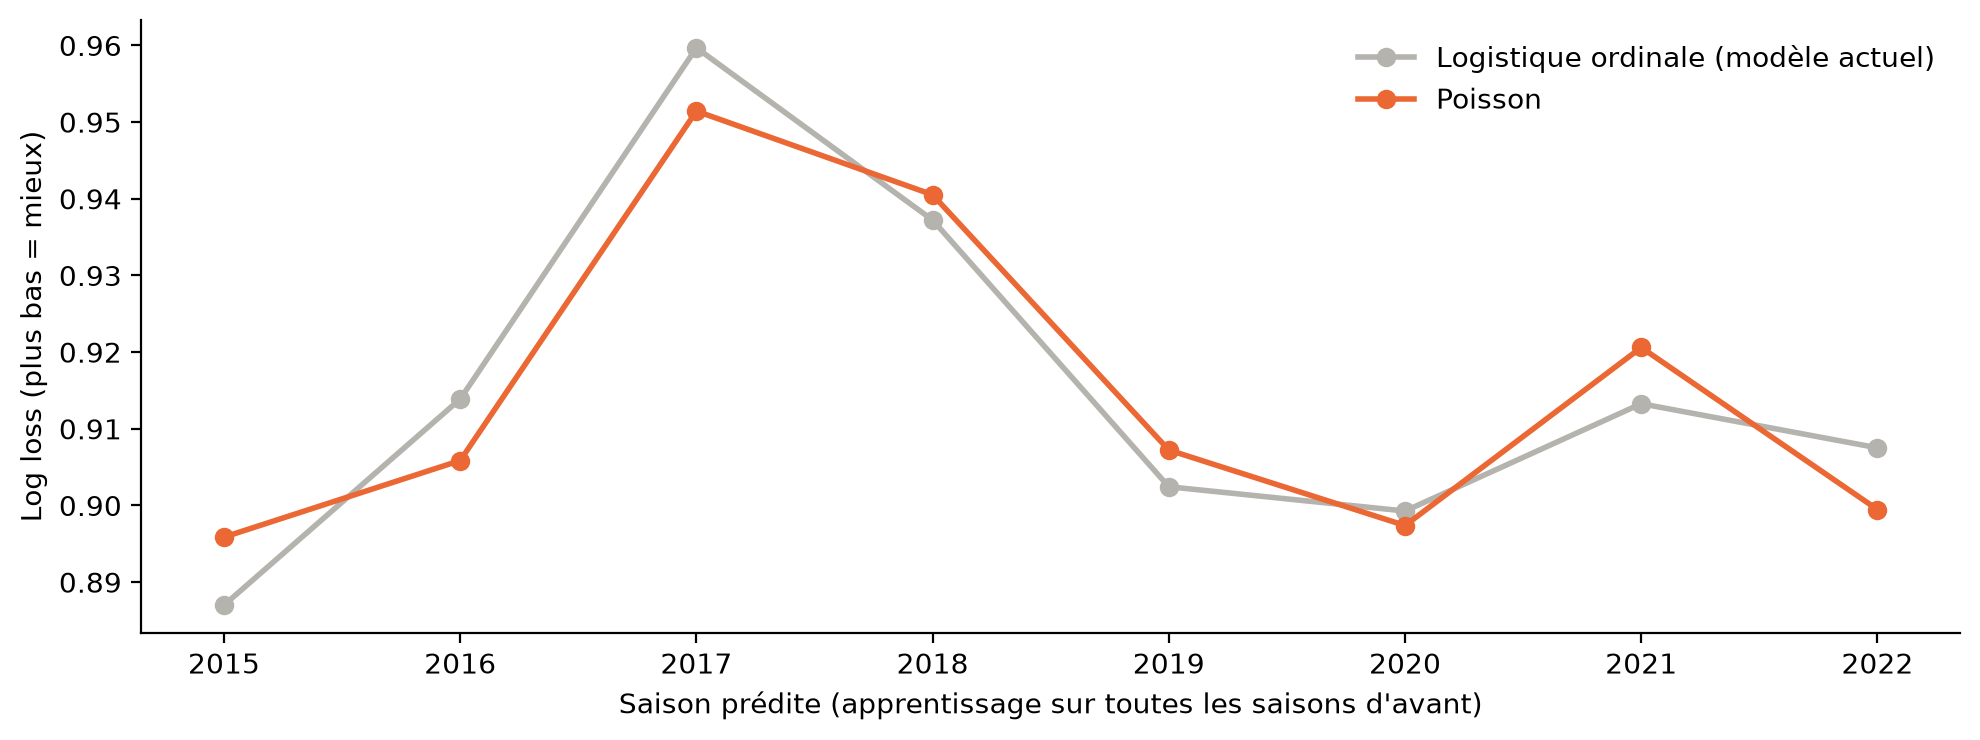

Validation glissante : 8 saisons, 994 matchs
MAE des buts (par équipe) : Poisson 0.983 | DummyRegressor 1.111


,log loss,RPS,accuracy,balanced accuracy,saisons où Poisson fait mieux
modèle,,,,,
Poisson,0.9148,0.1869,59.1%,48.9%,—
Logistique ordinale (modèle actuel),0.9151,0.1868,59.3%,48.7%,4 / 8
Dummy (fréquences passées),1.0536,0.2353,45.9%,33.3%,8 / 8


In [5]:
def mesures(y_vrai, probas):
    # Log loss, RPS et accuracy, calculés à la main pour qu'on voie exactement ce qu'on mesure
    p = probas[ISSUES].to_numpy()
    vrai = pd.Series(y_vrai).map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
    p_vrai = np.clip(p[np.arange(len(p)), vrai], 1e-15, 1)
    observe = np.eye(3)[vrai]
    rps = ((np.cumsum(p, axis=1)[:, :2] - np.cumsum(observe, axis=1)[:, :2]) ** 2).sum(axis=1) / 2
    predit = p.argmax(axis=1)
    return {'log loss': -np.log(p_vrai).mean(), 'RPS': rps.mean(), 'accuracy': (predit == vrai).mean(),
            'balanced accuracy': balanced_accuracy_score(vrai, predit)}

def mae_buts(masque_appr, masque_eval):
    # MAE des buts par équipe : Poisson contre DummyRegressor (moyenne de l'apprentissage, un par côté)
    _, l_d, l_e, _ = predire_poisson(masque_appr, masque_eval)
    appr, ev = g[masque_appr], g[masque_eval]
    reel = np.concatenate([ev['buts_dom'], ev['buts_ext']])
    dummy = np.concatenate([
        DummyRegressor(strategy='mean').fit(appr[['domicile']], appr['buts_dom']).predict(ev[['domicile']]),
        DummyRegressor(strategy='mean').fit(appr[['domicile']], appr['buts_ext']).predict(ev[['domicile']])])
    return {'MAE Poisson': mean_absolute_error(reel, np.concatenate([l_d, l_e])),
            'MAE DummyRegressor': mean_absolute_error(reel, dummy), 'matchs': masque_eval.sum()}

def predire_dummy(masque_appr, masque_eval):
    freq = g.loc[masque_appr, 'resultat'].value_counts(normalize=True)[ISSUES]
    return pd.DataFrame([freq.to_numpy()] * masque_eval.sum(), columns=ISSUES)

def predire_ordinale(masque_appr, masque_eval):
    ordre = ISSUES[::-1]                                          # extérieur < nul < domicile
    X = lambda d: np.column_stack([d['ecart_elo_complet'] / 100, d['domicile']])
    appr = g[masque_appr]
    rang = appr['resultat'].map({issue: i for i, issue in enumerate(ordre)}).to_numpy()
    ajust = OrderedModel(rang, X(appr), distr='logit').fit(method='bfgs', disp=False, maxiter=2000)
    p = ajust.model.predict(ajust.params, exog=X(g[masque_eval]))
    return pd.DataFrame(p, columns=ordre)[ISSUES]

MODELES = {
    'Dummy (fréquences passées)': predire_dummy,
    'Logistique ordinale (modèle actuel)': predire_ordinale,
    'Poisson': lambda a, e: predire_poisson(a, e)[0],
}

SAISONS_VALIDATION = range(2015, 2023)
lignes = []
for saison in SAISONS_VALIDATION:
    appr, a_predire = g['season'] < saison, g['season'] == saison
    for nom, predire in MODELES.items():
        lignes.append({'saison': saison, 'modèle': nom, 'matchs': a_predire.sum(),
                       **mesures(g.loc[a_predire, 'resultat'], predire(appr, a_predire))})
par_saison = pd.DataFrame(lignes)
mae_saisons = pd.DataFrame([mae_buts(g['season'] < s, g['season'] == s) for s in SAISONS_VALIDATION])

moyenne = lambda t: pd.Series({c: np.average(t[c], weights=t['matchs'])
                               for c in ['log loss', 'RPS', 'accuracy', 'balanced accuracy']})
glissante = par_saison.groupby('modèle').apply(moyenne).sort_values('log loss')
pivot = par_saison.pivot(index='saison', columns='modèle', values='log loss')
glissante['saisons où Poisson fait mieux'] = '—'
glissante.loc['Logistique ordinale (modèle actuel)', 'saisons où Poisson fait mieux'] = \
    f"{(pivot['Poisson'] < pivot['Logistique ordinale (modèle actuel)']).sum()} / {len(pivot)}"
glissante.loc['Dummy (fréquences passées)', 'saisons où Poisson fait mieux'] = \
    f"{(pivot['Poisson'] < pivot['Dummy (fréquences passées)']).sum()} / {len(pivot)}"

fig, ax = plt.subplots(figsize=(10, 3.8))
for nom, couleur in [('Logistique ordinale (modèle actuel)', GRIS), ('Poisson', ORANGE)]:
    ax.plot(pivot.index, pivot[nom], marker='o', color=couleur, linewidth=2, label=nom)
ax.set_xlabel("Saison prédite (apprentissage sur toutes les saisons d'avant)")
ax.set_ylabel('Log loss (plus bas = mieux)')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Validation glissante : {len(SAISONS_VALIDATION)} saisons, {par_saison.groupby('modèle')['matchs'].sum().iloc[0]} matchs")
print(f"MAE des buts (par équipe) : Poisson {np.average(mae_saisons['MAE Poisson'], weights=mae_saisons['matchs']):.3f} | "
      f"DummyRegressor {np.average(mae_saisons['MAE DummyRegressor'], weights=mae_saisons['matchs']):.3f}")
glissante.style.format({'log loss': '{:.4f}', 'RPS': '{:.4f}', 'accuracy': '{:.1%}', 'balanced accuracy': '{:.1%}'})

**Lecture :**
| Validation glissante (8 saisons, 994 matchs) | Log loss | RPS | Accuracy | Balanced accuracy |
|---|---|---|---|---|
| **Poisson** | **0,9148** | 0,1869 | 59,1 % | 48,9 % |
| Logistique ordinale (`MODEL_BASELINE`) | 0,9151 | 0,1868 | 59,3 % | 48,7 % |
| Dummy | 1,0536 | 0,2353 | 45,9 % | 33,3 % |

| Les buts (par équipe) | MAE |
|---|---|
| **Poisson** | **0,983 but** |
| `DummyRegressor` (moyenne) | 1,111 but |

- **Poisson et le modèle actuel sont à égalité** : 0,9148 contre 0,9151 de log loss, et Poisson fait mieux sur 4 saisons sur 8. Les deux utilisent la même information (l'écart d'Elo et le terrain), il est donc logique qu'ils trouvent le vainqueur aussi bien l'un que l'autre.
- **Les deux écrasent le Dummy**, sur les 8 saisons, y compris en balanced accuracy (49 % contre 33 %).
- **Sur les buts, Poisson se trompe 12 % de moins que le `DummyRegressor`** : 0,98 but d'erreur moyenne par équipe, contre 1,11. Une erreur proche d'un but paraît grande, mais un nombre de buts est un entier très variable : même en connaissant parfaitement le niveau des équipes, on ne peut pas descendre beaucoup plus bas.
- **Conclusion :** passer à Poisson ne coûte rien en précision. Ce qu'il apporte, ce sont les scores.

## 5. Test final sur 2023-2025

Le modèle apprend sur 2012-2022, puis prédit les 502 matchs de 2023 à 2025, qu'il n'a jamais vus. **On ne fait ce test qu'une fois** : on ne revient pas modifier le modèle après.

En plus des moyennes, on mesure si l'écart entre Poisson et le modèle actuel est **réel ou dû au hasard**. Pour ça, on fait un *bootstrap* : on retire 5 000 fois au hasard 502 matchs parmi les 502 (avec remise), et on recalcule l'écart à chaque fois. Si l'intervalle obtenu contient 0, les deux modèles sont à égalité.

In [6]:
avant_test, test = g['season'] <= 2022, g['season'] >= 2023
y_test = g.loc[test, 'resultat']

probas_test = {nom: predire(avant_test, test) for nom, predire in MODELES.items()}
proba_p, lam_dom_t, lam_ext_t, m_test = predire_poisson(avant_test, test)
resultats_test = pd.DataFrame({nom: mesures(y_test, p) for nom, p in probas_test.items()}).T

# Bootstrap apparié : écart de log loss Poisson − modèle actuel, match par match
def perte_par_match(probas):
    p = probas[ISSUES].to_numpy()
    vrai = y_test.map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
    return -np.log(p[np.arange(len(p)), vrai])

ecart = perte_par_match(probas_test['Poisson']) - perte_par_match(probas_test['Logistique ordinale (modèle actuel)'])
rng = np.random.default_rng(GRAINE)
tirages = rng.integers(0, len(ecart), size=(5000, len(ecart)))
ecarts_boot = ecart[tirages].mean(axis=1)
ic_bas, ic_haut = np.percentile(ecarts_boot, [2.5, 97.5])

n_test = test.sum()
marge = 1.96 * np.sqrt(0.58 * 0.42 / n_test)
print(f"Matchs de test : {n_test} | marge d'erreur d'une accuracy autour de 58 % : ± {marge:.1%}")
print(f"Écart de log loss Poisson − modèle actuel : {ecart.mean():+.4f} "
      f"(intervalle à 95 % : {ic_bas:+.4f} à {ic_haut:+.4f})")
mae_test = mae_buts(avant_test, test)
print(f"MAE des buts (par équipe) : Poisson {mae_test['MAE Poisson']:.3f} | DummyRegressor {mae_test['MAE DummyRegressor']:.3f}")
resultats_test.style.format({'log loss': '{:.3f}', 'RPS': '{:.4f}', 'accuracy': '{:.1%}', 'balanced accuracy': '{:.1%}'})

Matchs de test : 502 | marge d'erreur d'une accuracy autour de 58 % : ± 4.3%
Écart de log loss Poisson − modèle actuel : -0.0014 (intervalle à 95 % : -0.0073 à +0.0035)
MAE des buts (par équipe) : Poisson 1.026 | DummyRegressor 1.136


,log loss,RPS,accuracy,balanced accuracy
Dummy (fréquences passées),1.020,0.2359,50.0%,33.3%
Logistique ordinale (modèle actuel),0.904,0.1936,58.2%,44.7%
Poisson,0.902,0.1932,58.6%,45.5%


**La matrice de confusion, et la question de l'atelier.** Le prof propose comme cible « victoire à domicile, oui ou non ». Notre modèle y répond directement : P(victoire domicile) est l'une de ses trois probabilités. On prédit « oui » quand elle dépasse 50 %. La baseline est un `DummyClassifier(strategy="most_frequent")` appris sur 2012-2022.

In [7]:
# 1. Matrice de confusion à 3 issues (règle : l'issue la plus probable)
vrai_t = y_test.to_numpy()
predit_t = proba_p[ISSUES].idxmax(axis=1).to_numpy()
matrice = pd.DataFrame(confusion_matrix(vrai_t, predit_t, labels=ISSUES),
                       index=[f'vrai : {i}' for i in ISSUES], columns=[f'prédit : {i}' for i in ISSUES])
print("Matrice de confusion à 3 issues (test 2023-2025, nombre de matchs) :")
display(matrice)
rappel = pd.Series(np.diag(matrice.to_numpy()) / matrice.sum(axis=1).to_numpy(), index=ISSUES)
print("Taux de réussite par issue (rappel) : " + ', '.join(f"{i} {v:.0%}" for i, v in rappel.items()))

# 2. La version binaire : victoire à domicile, oui ou non
y_bin = (y_test == 'Victoire domicile').to_numpy()
pred_bin = (proba_p['Victoire domicile'] > 0.5).to_numpy()
cible_appr = g.loc[avant_test, 'resultat'] == 'Victoire domicile'
dummy_bin = DummyClassifier(strategy='most_frequent').fit(g.loc[avant_test, ['domicile']], cible_appr)
pred_dummy_bin = dummy_bin.predict(g.loc[test, ['domicile']])
print(f"\nVersion binaire : {cible_appr.mean():.1%} de victoires à domicile en 2012-2022, "
      f"donc la classe majoritaire est « {'oui' if dummy_bin.predict(g.loc[test, ['domicile']].head(1))[0] else 'non'} »")
display(pd.DataFrame(confusion_matrix(y_bin, pred_bin, labels=[True, False]),
                     index=['vrai : oui', 'vrai : non'], columns=['prédit : oui', 'prédit : non']))
pd.DataFrame({
    'Dummy (classe majoritaire)': {'accuracy': (pred_dummy_bin == y_bin).mean(),
                                   'balanced accuracy': balanced_accuracy_score(y_bin, pred_dummy_bin)},
    'Poisson (P > 50 %)': {'accuracy': (pred_bin == y_bin).mean(),
                           'balanced accuracy': balanced_accuracy_score(y_bin, pred_bin)},
}).T.style.format('{:.1%}')

Matrice de confusion à 3 issues (test 2023-2025, nombre de matchs) :


,prédit : Victoire domicile,prédit : Nul,prédit : Victoire extérieur
vrai : Victoire domicile,201,0,50
vrai : Nul,56,0,30
vrai : Victoire extérieur,72,0,93


Taux de réussite par issue (rappel) : Victoire domicile 80%, Nul 0%, Victoire extérieur 56%

Version binaire : 46.7% de victoires à domicile en 2012-2022, donc la classe majoritaire est « non »


,prédit : oui,prédit : non
vrai : oui,147,104
vrai : non,56,195


,accuracy,balanced accuracy
Dummy (classe majoritaire),50.0%,50.0%
Poisson (P > 50 %),68.1%,68.1%


**Lecture :**
- **Le modèle ne prédit jamais le nul** : 0 nul trouvé sur 86. Même entre deux équipes de même niveau, la probabilité de nul plafonne vers 24 %, toujours en dessous de celle d'une victoire. Avec la règle « l'issue la plus probable », le nul ne sort donc jamais. C'est ce qui fait tomber la balanced accuracy à 45,5 %, alors que l'accuracy est de 58,6 %.
- **Sur les victoires, il est solide** : il trouve 80 % des victoires à domicile et 56 % des victoires à l'extérieur.
- **Pourquoi on ne « force » pas des nuls :** on pourrait prédire « nul » dès que sa probabilité dépasse un seuil, réglé sur la validation. La balanced accuracy monterait, mais au prix de victoires mal prédites. Et surtout, la simulation n'utilise pas ces prédictions : elle **tire** les scores selon les probabilités, et les nuls y apparaissent avec la bonne fréquence (section 6).
- **La question de l'atelier, « victoire à domicile oui/non »** : notre modèle y répond avec **68,1 %** d'accuracy et 68,1 % de balanced accuracy, contre 50,0 % pour le Dummy. La classe majoritaire de 2012-2022 est « non » (46,7 % de victoires à domicile seulement) : le Dummy prédit donc toujours « pas de victoire à domicile ». Prédire des scores ne nous a rien fait perdre sur la question de départ.

**Le modèle est-il aussi bon en élimination directe ?** C'est là que se joue le titre. L'audit de Loan a montré que, sur le test seul, le gain sur le Dummy en élimination directe n'est pas démontré (118 matchs, intervalle qui contient 0). On regarde donc aussi la validation glissante, qui contient presque deux fois plus de matchs à élimination directe. Le gain est la log loss du Dummy moins celle du modèle, match par match (plus c'est grand, mieux c'est), avec un intervalle à 95 % par bootstrap.

In [8]:
def gains_sur_dummy(masque_appr, masque_eval):
    # Gain de log loss du modèle sur le Dummy, match par match
    y = g.loc[masque_eval, 'resultat'].map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
    perte = lambda p: -np.log(p[ISSUES].to_numpy()[np.arange(len(y)), y])
    return perte(predire_dummy(masque_appr, masque_eval)) - perte(predire_poisson(masque_appr, masque_eval)[0])

def intervalle(x, n_tirages=5000):
    tirages = np.random.default_rng(GRAINE).integers(0, len(x), size=(n_tirages, len(x)))
    return np.percentile(x[tirages].mean(axis=1), [2.5, 97.5])

blocs = {'validation 2015-2022': [(g['season'] < s, g['season'] == s) for s in SAISONS_VALIDATION],
         'test 2023-2025': [(avant_test, test)]}
lignes_phase = []
for periode, decoupages in blocs.items():
    gains = np.concatenate([gains_sur_dummy(a, e) for a, e in decoupages])
    ko = np.concatenate([g.loc[e, 'elimination_directe'].to_numpy() for _, e in decoupages])
    ecarts = np.concatenate([g.loc[e, 'ecart_elo_complet'].abs().to_numpy() for _, e in decoupages])
    for phase, masque in [('groupes / phase de ligue', ~ko), ('élimination directe', ko)]:
        bas, haut = intervalle(gains[masque])
        lignes_phase.append({'période': periode, 'phase': phase, 'matchs': masque.sum(),
                             "écart d'Elo moyen": ecarts[masque].mean(), 'gain sur le Dummy': gains[masque].mean(),
                             'IC 95 % bas': bas, 'IC 95 % haut': haut, 'démontré ?': 'oui' if bas > 0 else 'non'})
pd.DataFrame(lignes_phase).set_index(['période', 'phase']).style.format(
    {"écart d'Elo moyen": '{:.0f}', 'gain sur le Dummy': '{:+.3f}', 'IC 95 % bas': '{:+.3f}', 'IC 95 % haut': '{:+.3f}'})

**Lecture :**
| Gain sur le Dummy | Groupes / phase de ligue | Élimination directe |
|---|---|---|
| Validation 2015-2022 | **+0,160** (768 matchs) ✅ | **+0,068** (226 matchs) ✅ |
| Test 2023-2025 | **+0,143** (384 matchs) ✅ | +0,034 (118 matchs) ❌ intervalle de −0,043 à +0,106 |

- **En phase de groupes et de ligue, le modèle bat nettement le Dummy**, sur la validation comme sur le test.
- **En élimination directe, le gain est démontré sur la validation** (226 matchs, intervalle entièrement au-dessus de 0), **mais pas sur le test** : 118 matchs, c'est trop peu pour conclure. Le gain est positif dans les deux cas.
- **Le gain y est plus petit, surtout parce que les matchs sont plus serrés** : 113 à 121 points d'écart d'Elo moyen, contre 149 à 170 en phase de groupes. Entre deux équipes proches, aucun modèle ne peut beaucoup mieux faire que le hasard. À écart d'Elo égal, le gain est du même ordre dans les deux phases : sur le test, pour les matchs à moins de 150 points d'écart, +0,029 en phase de groupes contre +0,027 en élimination directe (sur de petits groupes : 218 et 78 matchs).
- **Pourquoi c'est important :** c'est en élimination directe que se joue le titre. Les probabilités de titre de la simulation reposent donc sur la partie du modèle la moins bien démontrée. À dire clairement.

**Lecture :**
| Test (2023-2025, 502 matchs) | Log loss | RPS | Accuracy | Balanced accuracy | MAE des buts |
|---|---|---|---|---|---|
| **Poisson** | **0,902** | **0,1932** | **58,6 %** | **45,5 %** | **1,026** |
| Logistique ordinale (`MODEL_BASELINE`) | 0,904 | 0,1936 | 58,2 % | 44,7 % | — |
| Dummy / `DummyRegressor` | 1,020 | 0,2359 | 50,0 % | 33,3 % | 1,136 |

- **Le test confirme la validation** : Poisson est légèrement devant sur toutes les mesures, et très loin devant le Dummy.
- **Mais l'écart avec le modèle actuel n'est pas réel** : −0,0014 de log loss, avec un intervalle à 95 % de −0,0073 à +0,0035, qui contient 0. De même, 0,4 point d'accuracy représente 2 matchs sur 502, bien en dessous de la marge d'erreur (± 4,3 points).
- **Conclusion :** égalité sur le vainqueur. On garde Poisson pour ce qu'il ajoute.

## 6. Les scores prédits sont-ils réalistes ?

C'est la vraie question de ce notebook. Une bonne log loss dit que le modèle trouve le bon vainqueur ; elle ne dit pas que les **scores** sont crédibles. Or la simulation va s'en servir pour la différence de buts et les matchs aller-retour.

On compare, sur les 502 matchs de test, ce que le modèle prévoit à ce qui s'est passé :
1. le nombre moyen de buts ;
2. la fréquence de chaque score (1-0, 1-1, 2-1…) ;
3. la répartition du **nombre total de buts** et de la **différence de buts** ;
4. la **calibration** : quand le modèle annonce 60 % de victoire à domicile, l'équipe gagne-t-elle vraiment environ 6 fois sur 10 ?

In [9]:
reel = g.loc[test, ['buts_dom', 'buts_ext']].to_numpy().astype(int)

# 1. Buts moyens
buts = pd.DataFrame({'prévu': [lam_dom_t.mean(), lam_ext_t.mean()], 'réel': reel.mean(axis=0)},
                    index=['équipe qui reçoit', 'équipe qui se déplace'])
print("Buts moyens par match (test 2023-2025) :")
print(buts.round(2).to_string())

# 2. Fréquence des scores : moyenne des grilles prévues contre fréquence observée
grille_moy = m_test.mean(axis=0)
obs = np.zeros_like(grille_moy)
np.add.at(obs, (np.minimum(reel[:, 0], MAX_BUTS), np.minimum(reel[:, 1], MAX_BUTS)), 1)
obs /= len(reel)
freq_scores = pd.DataFrame([{'score': f'{i}-{j}', 'prévu (%)': grille_moy[i, j] * 100, 'réel (%)': obs[i, j] * 100}
                            for i in range(MAX_BUTS + 1) for j in range(MAX_BUTS + 1)])
freq_scores = freq_scores.sort_values('réel (%)', ascending=False).head(10).set_index('score')

# Score exact : le score le plus probable du modèle, contre la règle « toujours le score le plus fréquent »
score_predit = np.array([np.unravel_index(m.argmax(), m.shape) for m in m_test])
exact_modele = (score_predit == reel).all(axis=1).mean()
appr = g[avant_test]
plus_frequent = (appr['buts_dom'].astype(str) + '-' + appr['buts_ext'].astype(str)).value_counts().index[0]
exact_naif = ((g.loc[test, 'buts_dom'].astype(str) + '-' + g.loc[test, 'buts_ext'].astype(str)) == plus_frequent).mean()
print(f"\nScore exact trouvé : {exact_modele:.1%} des matchs (règle « toujours {plus_frequent} » : {exact_naif:.1%})")
print(f"Nuls : {issues_depuis_scores(m_test)['Nul'].mean():.1%} prévus en moyenne, {(y_test == 'Nul').mean():.1%} réels")
freq_scores.round(1)

Buts moyens par match (test 2023-2025) :
                       prévu  réel
équipe qui reçoit       1.65  1.87
équipe qui se déplace   1.29  1.41

Score exact trouvé : 9.8% des matchs (règle « toujours 1-1 » : 6.6%)
Nuls : 21.6% prévus en moyenne, 17.1% réels


,prévu (%),réel (%)
score,,
1-0,8.5,9.0
2-1,8.0,7.8
2-0,7.3,7.0
1-1,10.2,6.6
1-2,6.7,5.8
0-1,7.2,5.8
3-1,4.6,5.4
2-3,2.1,5.2
0-0,5.4,4.8


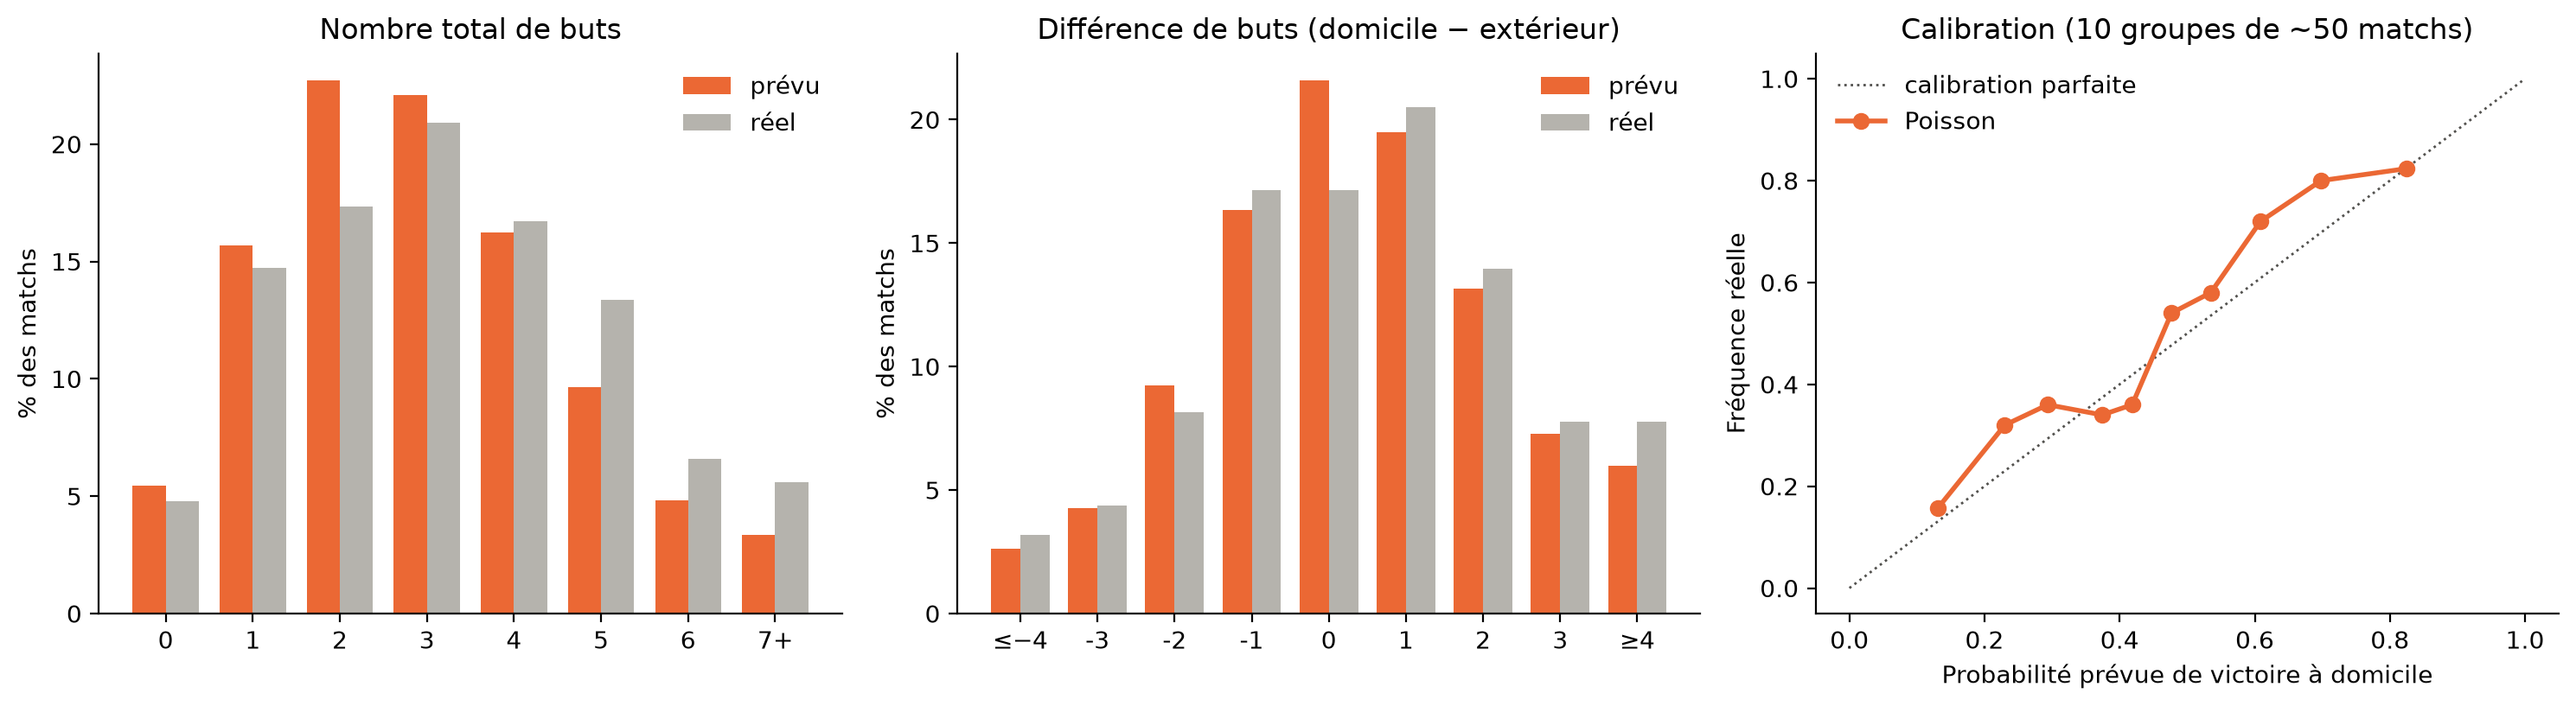

In [10]:
# 3. Total de buts et différence de buts : prévu contre réel
i, j = np.meshgrid(K, K, indexing='ij')
total_prevu = pd.Series(grille_moy.ravel()).groupby(np.minimum(i + j, 7).ravel()).sum()
total_reel = pd.Series(np.minimum(reel.sum(axis=1), 7)).value_counts(normalize=True).reindex(range(8), fill_value=0)
diff_prevu = pd.Series(grille_moy.ravel()).groupby(np.clip(i - j, -4, 4).ravel()).sum()
diff_reel = pd.Series(np.clip(reel[:, 0] - reel[:, 1], -4, 4)).value_counts(normalize=True).reindex(range(-4, 5), fill_value=0)

# 4. Calibration de la probabilité de victoire à domicile, par groupe de 10 % des matchs
calib = pd.DataFrame({'prévu': proba_p['Victoire domicile'].to_numpy(),
                      'réel': (y_test == 'Victoire domicile').to_numpy()})
calib['groupe'] = pd.qcut(calib['prévu'], 10, labels=False, duplicates='drop')
calib = calib.groupby('groupe').agg(prévu=('prévu', 'mean'), réel=('réel', 'mean'), matchs=('réel', 'size'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
largeur = 0.38
for ax, prevu, vrai, titre, etiquettes in [
    (axes[0], total_prevu, total_reel, 'Nombre total de buts', [str(k) for k in range(7)] + ['7+']),
    (axes[1], diff_prevu, diff_reel, 'Différence de buts (domicile − extérieur)', ['≤−4'] + [str(k) for k in range(-3, 4)] + ['≥4']),
]:
    x = np.arange(len(prevu))
    ax.bar(x - largeur / 2, prevu.to_numpy() * 100, largeur, color=ORANGE, label='prévu')
    ax.bar(x + largeur / 2, vrai.to_numpy() * 100, largeur, color=GRIS, label='réel')
    ax.set_xticks(x, etiquettes)
    ax.set_title(titre)
    ax.set_ylabel('% des matchs')
    ax.legend(frameon=False)
axes[2].plot([0, 1], [0, 1], color=ENCRE, linestyle=':', linewidth=1, label='calibration parfaite')
axes[2].plot(calib['prévu'], calib['réel'], marker='o', color=ORANGE, linewidth=2, label='Poisson')
axes[2].set_xlabel('Probabilité prévue de victoire à domicile')
axes[2].set_ylabel('Fréquence réelle')
axes[2].set_title('Calibration (10 groupes de ~50 matchs)')
axes[2].legend(frameon=False, loc='upper left')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture :**
- **Le score exact** est trouvé dans **9,8 %** des matchs, contre 6,6 % pour la règle « toujours 1-1 ». Ça paraît peu, mais il y a des dizaines de scores possibles.
- **La forme des scores est juste** : 1-0, 2-1, 2-0, 3-0 et 0-0 sont prévus à moins d'un point de leur fréquence réelle. La **différence de buts** est proche de la réalité, sauf pour le 0 (le nul).
- **La calibration est bonne aux extrêmes** : quand le modèle annonce 15 % ou 80 % de victoire à domicile, c'est ce qui se passe. Au milieu (45 à 70 %), l'équipe qui reçoit gagne un peu plus souvent que prévu.
- **Deux défauts, liés entre eux :**
  1. **les buts sont sous-estimés** : 1,65 et 1,29 prévus, pour 1,87 et 1,41 réels. Le modèle prévoit trop de matchs à 2 buts (22,7 % contre 17,3 %) et pas assez à 5 buts ou plus ;
  2. **les nuls sont surestimés** : 21,6 % prévus, 17,1 % réels, et surtout le 1-1 (10,2 % contre 6,6 %).

  Moins de buts, c'est mécaniquement plus de nuls. La section suivante montre d'où vient ce manque de buts.

## 7. Depuis le nouveau format, on observe plus de buts

La section 6 montre que le modèle **sous-estime les buts** sur le test. On regarde saison par saison pour comprendre d'où ça vient.

> ⚠️ **Transparence :** c'est en regardant le test 2023-2025 (section 6) qu'on a repéré ce problème. Le test a donc servi à **orienter** une décision, ce qu'un test ne devrait pas faire. Pour rester honnêtes : les résultats des sections 5 et 6 concernent le modèle « Elo + terrain », choisi **avant** de regarder le test ; et la variable « nouveau format » n'est justifiée **que** par un test vers l'avant, sur une saison que le modèle n'avait pas vue (ci-dessous). Il n'existe pas de données plus récentes jamais vues : les matchs 2026-2027 ne sont pas dans le fichier.

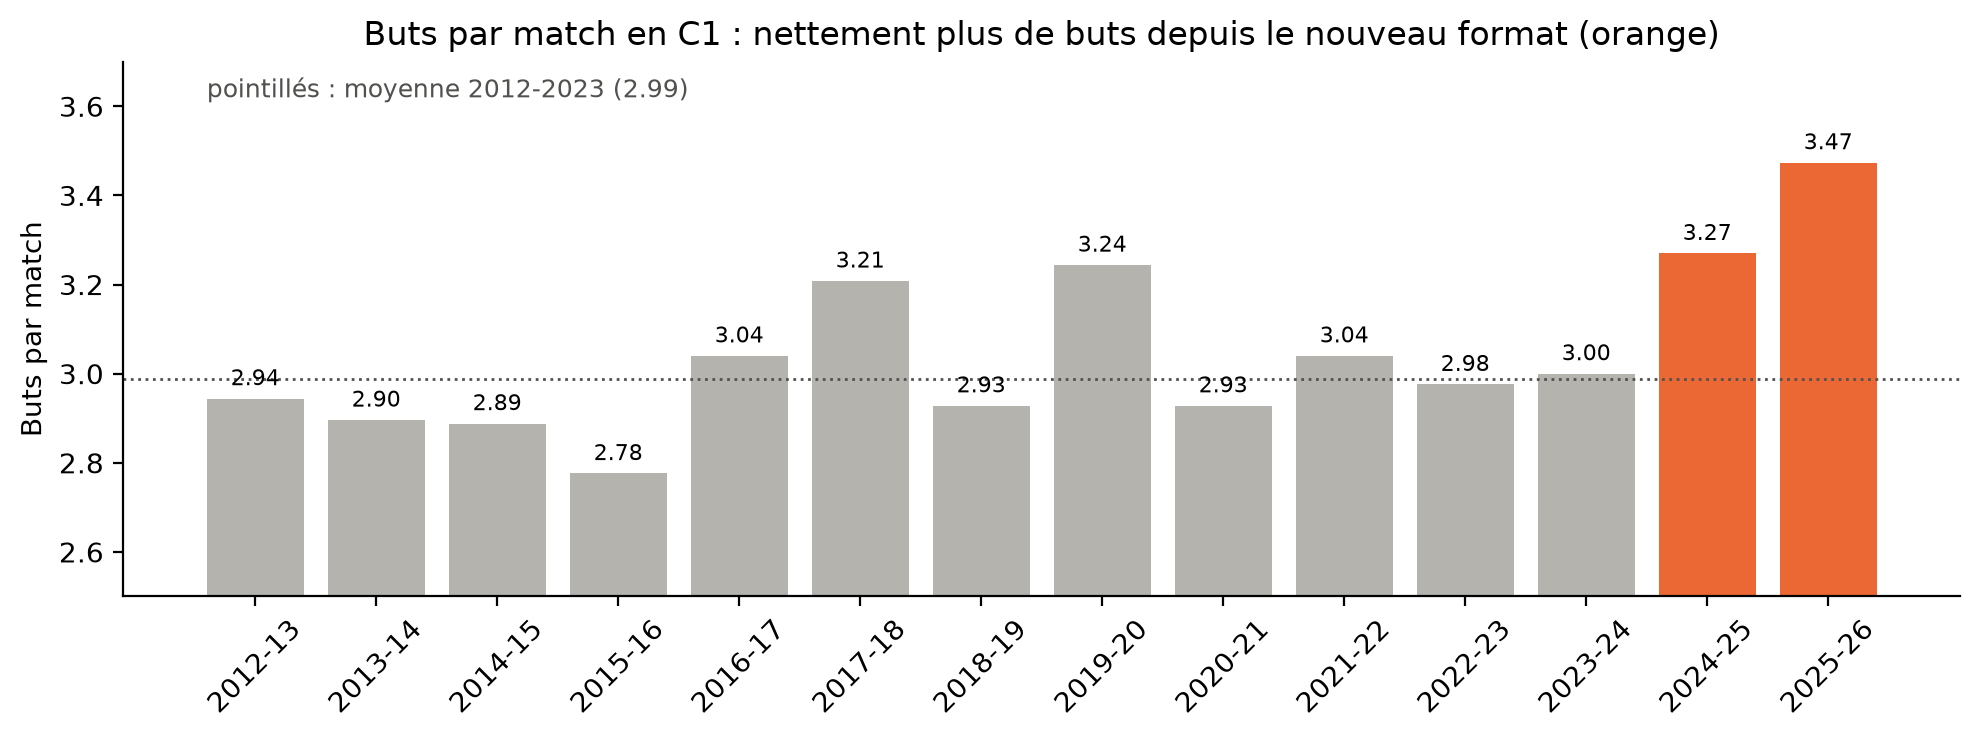

,buts par match,nuls,ecart_elo_moyen
season,,,
2020,2.93,19.2%,160
2021,3.04,20.8%,158
2022,2.98,20.8%,138
2023,3.00,21.6%,135
2024,3.27,13.8%,139
2025,3.47,17.6%,145


In [11]:
par_saison_buts = g.groupby('season').agg(dom=('buts_dom', 'mean'), ext=('buts_ext', 'mean'),
                                          nuls=('resultat', lambda r: (r == 'Nul').mean()),
                                          ecart_elo_moyen=('ecart_elo_complet', lambda e: e.abs().mean()))
par_saison_buts['buts par match'] = par_saison_buts['dom'] + par_saison_buts['ext']
avant = par_saison_buts.loc[:2023, 'buts par match'].mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
couleurs = [ORANGE if s >= 2024 else GRIS for s in par_saison_buts.index]
ax.bar(par_saison_buts.index, par_saison_buts['buts par match'], color=couleurs)
ax.axhline(avant, color=ENCRE, linestyle=':', linewidth=1)
ax.text(2011.6, 3.62, f"pointillés : moyenne 2012-2023 ({avant:.2f})", fontsize=9, color=ENCRE)
for s, v in par_saison_buts['buts par match'].items():
    ax.text(s, v + 0.03, f"{v:.2f}", ha='center', fontsize=8)
ax.set_ylim(2.5, 3.7)
ax.set_xticks(par_saison_buts.index, [f"{s}-{str(s + 1)[2:]}" for s in par_saison_buts.index], rotation=45)
ax.set_ylabel('Buts par match')
ax.set_title('Buts par match en C1 : nettement plus de buts depuis le nouveau format (orange)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
par_saison_buts[['buts par match', 'nuls', 'ecart_elo_moyen']].loc[2020:].style.format(
    {'buts par match': '{:.2f}', 'nuls': '{:.1%}', 'ecart_elo_moyen': '{:.0f}'})

**Lecture :**
- **Jusqu'en 2023-2024, le nombre de buts est stable** : entre 2,78 et 3,24 par match, 2,99 en moyenne.
- **Depuis le nouveau format, il saute** : **3,27** en 2024-2025, puis **3,47** en 2025-2026. Les nuls baissent en même temps (13,8 % et 17,6 %, contre environ 21 % avant).
- **Ce n'est pas dû à des matchs plus déséquilibrés** : l'écart d'Elo moyen entre les deux équipes n'a pas augmenté (139 et 145 points, contre 135 à 160 avant). À niveau égal, on marque simplement plus.
- **Le modèle ne peut pas le voir** : il moyenne toutes les saisons, dont 12 dans l'ancien format. C'est pour ça qu'il sous-estime les buts sur le test, qui contient 2 saisons du nouveau format sur 3.

**Le test honnête :** on apprend sur toutes les saisons jusqu'à 2024-2025, la seule saison du nouveau format connue à ce moment-là, puis on prédit **2025-2026**, que le modèle n'a jamais vue. On compare le modèle sans et avec la variable « nouveau format ».

Pour juger les **scores**, on ajoute une mesure : la **log loss des buts**, la même idée que la log loss, appliquée au nombre de buts de chaque équipe. Plus bas = des scores mieux prévus.

In [12]:
from scipy.stats import poisson

def log_loss_buts(lam_dom, lam_ext, d):
    # Log loss des buts réellement marqués par les deux équipes, moyenne par match
    return -(poisson.logpmf(d['buts_dom'], lam_dom) + poisson.logpmf(d['buts_ext'], lam_ext)).mean()

appr_25, saison_25 = g['season'] <= 2024, g['season'] == 2025
d25 = g[saison_25]
comparaison_format = {}
for nom, variables in [('Poisson (Elo + terrain)', VARIABLES), ('Poisson + nouveau format', VARIABLES + ['nouveau_format'])]:
    probas, l_d, l_e, _ = predire_poisson(appr_25, saison_25, variables)
    comparaison_format[nom] = {**mesures(d25['resultat'], probas), 'log loss des buts': log_loss_buts(l_d, l_e, d25),
                               'buts prévus': (l_d + l_e).mean(), 'nuls prévus': probas['Nul'].mean()}
comparaison_format = pd.DataFrame(comparaison_format).T
comparaison_format['buts réels'] = (d25['buts_dom'] + d25['buts_ext']).mean()
comparaison_format['nuls réels'] = (d25['resultat'] == 'Nul').mean()
print(f"Prédiction de la saison 2025-2026 ({saison_25.sum()} matchs), apprentissage sur 2012-2024")
comparaison_format[['log loss', 'RPS', 'log loss des buts', 'buts prévus', 'buts réels', 'nuls prévus', 'nuls réels']].style.format(
    {'log loss': '{:.4f}', 'RPS': '{:.4f}', 'log loss des buts': '{:.4f}', 'buts prévus': '{:.2f}', 'buts réels': '{:.2f}',
     'nuls prévus': '{:.1%}', 'nuls réels': '{:.1%}'})

Prédiction de la saison 2025-2026 (188 matchs), apprentissage sur 2012-2024


,log loss,RPS,log loss des buts,buts prévus,buts réels,nuls prévus,nuls réels
Poisson (Elo + terrain),0.9320,0.1998,3.3045,2.98,3.47,21.4%,17.6%
Poisson + nouveau format,0.9304,0.1996,3.2730,3.27,3.47,20.0%,17.6%


**Le gain est-il réel ?** L'audit de Loan a montré que, pour trouver le vainqueur, le gain de la variable n'est pas démontré. On mesure donc les deux gains séparément, match par match, avec un intervalle à 95 % : sur le **vainqueur** (log loss des issues) et sur les **scores** (log loss des buts), qui est la raison d'être de la variable.

In [13]:
def pertes_2025(variables):
    probas, l_d, l_e, _ = predire_poisson(appr_25, saison_25, variables)
    y = d25['resultat'].map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
    issues = -np.log(probas[ISSUES].to_numpy()[np.arange(len(y)), y])
    buts = -(poisson.logpmf(d25['buts_dom'], l_d) + poisson.logpmf(d25['buts_ext'], l_e))
    return issues, buts

sans_issues, sans_buts = pertes_2025(VARIABLES)
avec_issues, avec_buts = pertes_2025(VARIABLES + ['nouveau_format'])
gain_format = pd.DataFrame([
    {'ce qu\'on mesure': nom, 'gain moyen': x.mean(), 'IC 95 % bas': intervalle(x)[0], 'IC 95 % haut': intervalle(x)[1]}
    for nom, x in [('le vainqueur (log loss des issues)', sans_issues - avec_issues),
                   ('les scores (log loss des buts)', sans_buts - avec_buts)]]).set_index("ce qu'on mesure")
gain_format['démontré ?'] = np.where(gain_format['IC 95 % bas'] > 0, 'oui', 'non')
print(f"Gain de la variable « nouveau format » sur 2025-2026 ({saison_25.sum()} matchs), match par match :")
gain_format.style.format({'gain moyen': '{:+.4f}', 'IC 95 % bas': '{:+.4f}', 'IC 95 % haut': '{:+.4f}'})

Gain de la variable « nouveau format » sur 2025-2026 (188 matchs), match par match :


,gain moyen,IC 95 % bas,IC 95 % haut,démontré ?
ce qu'on mesure,,,,
le vainqueur (log loss des issues),+0.0016,-0.0037,+0.0066,non
les scores (log loss des buts),+0.0315,+0.0065,+0.0580,oui


**Lecture :**
| Prédiction de 2025-2026 (188 matchs) | Log loss | Log loss des buts | Buts prévus | Nuls prévus |
|---|---|---|---|---|
| Poisson (Elo + terrain) | 0,9320 | 3,3045 | 2,98 | 21,4 % |
| **Poisson + nouveau format** | **0,9304** | **3,2730** | **3,27** | **20,0 %** |
| *Réel* | | | *3,47* | *17,6 %* |

| Gain de la variable, match par match | Gain moyen | Intervalle à 95 % | Démontré ? |
|---|---|---|---|
| sur le **vainqueur** (log loss des issues) | +0,0016 | −0,0037 à +0,0066 | ❌ non |
| sur les **scores** (log loss des buts) | **+0,0315** | **+0,0065 à +0,0580** | ✅ oui |

- **Pour trouver le vainqueur, la variable ne change rien de démontrable** : l'intervalle contient 0. C'est logique : elle augmente les buts des **deux** équipes à la fois, donc elle ne change presque pas qui gagne.
- **Pour les scores, le gain est réel** : 3,27 buts prévus au lieu de 2,98 (pour 3,47 réels), et un intervalle entièrement au-dessus de 0. C'est exactement son rôle : donner le bon nombre de buts, pour la différence de buts et les matchs aller-retour de la simulation.
- **Elle ne corrige pas tout** : apprise sur une seule saison, elle reste en dessous de la réalité. Le modèle final l'apprend sur les deux saisons du nouveau format et l'estime plus forte (× 1,14 au lieu de × 1,11).
- **Pourquoi c'est un test honnête, et sa limite :** l'effet a été appris sur 2024-2025 et jugé sur 2025-2026, une saison que le modèle n'avait pas vue. Mais l'idée de cette variable est venue en regardant le test (voir l'encadré plus haut), et 188 matchs restent peu.
- **Décision :** on garde la variable dans le modèle final, **pour les scores**. Elle est connue avant le match (on sait dans quel format on joue), et 2026-2027 est dans le nouveau format.

## 8. La forme récente apporte-t-elle quelque chose ?

La **forme récente** fait partie des variables proposées par le prof. Loan la calcule dans `v2_forme.ipynb` : l'écart, entre les deux équipes, de points moyens par match sur leurs 5 derniers matchs officiels, joués **strictement avant** la date du match et dans les **60 jours** qui précèdent (un match gagné aux tirs au but compte comme un nul) (`ecart_forme_5`, fichier `output/forme_par_match.csv`).

**La règle, fixée avant de voir le résultat :** on garde la variable seulement si elle améliore la log loss moyenne de la validation glissante **et** si elle fait mieux sur **au moins 5 saisons sur 8**. Sinon, on la rejette : une variable de plus qui n'aide pas ajoute du bruit et une source d'erreur.

Si le fichier n'existe pas encore, cette section est sautée sans erreur.

In [14]:
CHEMIN_FORME = '../output/forme_par_match.csv'
garder_forme = False
if os.path.exists(CHEMIN_FORME):
    forme = pd.read_csv(CHEMIN_FORME, encoding='utf-8-sig').set_index('game_id')['ecart_forme_5']
    g['ecart_forme_5'] = g['game_id'].map(forme)
    print(f"Forme récente chargée : {g['ecart_forme_5'].notna().mean():.1%} des matchs renseignés "
          f"(les manquants sont remplacés par la médiane de l'apprentissage, dans le Pipeline)")
    print(f"Corrélation avec l'écart d'Elo : {g[['ecart_forme_5', 'ecart_elo_complet']].corr().iloc[0, 1]:.2f}")
    comparaison_forme = []
    for saison in SAISONS_VALIDATION:
        appr, a_predire = g['season'] < saison, g['season'] == saison
        sans = mesures(g.loc[a_predire, 'resultat'], predire_poisson(appr, a_predire)[0])['log loss']
        avec = mesures(g.loc[a_predire, 'resultat'], predire_poisson(appr, a_predire, VARIABLES + ['ecart_forme_5'])[0])['log loss']
        comparaison_forme.append({'saison': saison, 'matchs': a_predire.sum(), 'sans la forme': sans, 'avec la forme': avec})
    comparaison_forme = pd.DataFrame(comparaison_forme).set_index('saison')
    moy_sans = np.average(comparaison_forme['sans la forme'], weights=comparaison_forme['matchs'])
    moy_avec = np.average(comparaison_forme['avec la forme'], weights=comparaison_forme['matchs'])
    nb_mieux = (comparaison_forme['avec la forme'] < comparaison_forme['sans la forme']).sum()
    garder_forme = (moy_avec < moy_sans) and (nb_mieux >= 5)
    print(f"Log loss moyenne : sans {moy_sans:.4f} | avec {moy_avec:.4f} | meilleure sur {nb_mieux} saisons sur 8")
    print("Décision :", "on GARDE la forme récente" if garder_forme else "on REJETTE la forme récente")
    display(comparaison_forme.round(4))
else:
    print(f"{CHEMIN_FORME} n'existe pas encore (travail de Loan) : section sautée, le modèle reste sans la forme récente.")

Forme récente chargée : 99.0% des matchs renseignés (les manquants sont remplacés par la médiane de l'apprentissage, dans le Pipeline)
Corrélation avec l'écart d'Elo : 0.44


Log loss moyenne : sans 0.9148 | avec 0.9156 | meilleure sur 4 saisons sur 8
Décision : on REJETTE la forme récente


,matchs,sans la forme,avec la forme
saison,,,
2015,125,0.8959,0.8945
2016,125,0.9059,0.9042
2017,125,0.9514,0.9568
2018,125,0.9405,0.9397
2019,119,0.9072,0.9115
2020,125,0.8974,0.8986
2021,125,0.9206,0.9229
2022,125,0.8995,0.8964


**Lecture :**
| Validation glissante (8 saisons) | Log loss moyenne | Saisons où la forme fait mieux |
|---|---|---|
| Poisson sans la forme | **0,9148** | — |
| Poisson avec la forme | 0,9156 | 4 sur 8 |

- **La forme récente est rejetée**, par la règle fixée avant de voir le résultat : elle n'améliore pas la log loss moyenne (0,9156 contre 0,9148), et ne fait mieux que sur 4 saisons sur 8.
- **Pourquoi elle n'apporte rien :** elle suit l'Elo (corrélation de 0,44). L'Elo est mis à jour après chaque match, c'est déjà une forme lissée. Une fois l'Elo connu, il ne reste presque rien : l'audit de Loan trouve un lien de +0,035 avec le résultat, sous la marge du hasard (± 0,046).
- **Le résultat est solide :** l'audit de Loan le reproduit à l'identique, et la décision ne change pas quand on retire les clubs dont le championnat manque dans les données.
- **Ce n'est pas un échec :** une variable testée proprement puis rejetée, c'est une conclusion. Elle confirme que l'Elo contient déjà presque toute l'information utile.

## 9. Les pistes du prof : Dixon-Coles, blend, Poisson bivarié, fine-tuning

Le prof nous a proposé d'améliorer le modèle de trois façons. On les teste toutes, avec **le même protocole** que le reste du notebook : validation glissante sur 8 saisons (2015-2022), test non touché, et **le même critère de choix**, la log loss du vainqueur. On regarde aussi la **log loss des scores exacts** : la probabilité donnée au score réellement observé.

| Piste | L'idée | Ce qu'elle pourrait corriger |
|---|---|---|
| **Dixon-Coles** (1997) | multiplier les 4 petits scores (0-0, 1-0, 0-1, 1-1) par un facteur qui dépend d'un paramètre ρ, **estimé sur les données** | le Poisson simple suppose les buts indépendants, ce qui est discutable pour les petits scores |
| **Blend** | mélanger les probabilités : w × Dixon-Coles + (1 − w) × Poisson | prendre le meilleur des deux |
| **Poisson bivarié** (Karlis et Ntzoufras, 2003) | les buts de chaque équipe = une part propre + une **part commune** λ₃ aux deux équipes | les matchs « ouverts », où les deux équipes marquent plus : une corrélation entre les buts |
| **Fine-tuning** | ajuster la forme du modèle : un terme en écart d'Elo au carré, ou un avantage du terrain propre à l'élimination directe | un effet de l'Elo pas tout à fait linéaire, un terrain différent dans les matchs à enjeu |
| **Pondération** | donner plus de poids aux saisons récentes (demi-vie de 3 saisons) | l'évolution du jeu, sans variable « format » |

**La règle, la même que pour la forme récente :** une piste n'est gardée que si elle améliore la log loss moyenne du vainqueur **et** fait mieux sur au moins 5 saisons sur 8.

**⚠️ Un piège à garder en tête :** on teste ici **6 variantes à la fois**. Même si aucune n'aidait vraiment, il serait assez probable que l'une d'elles passe la règle par hasard. Une piste qui passe doit donc être **confirmée une fois** sur le test.

In [15]:
from scipy.optimize import minimize
from math import lgamma

def pertes_grilles(m, d):
    # Log loss du vainqueur et des scores exacts, match par match, à partir des grilles de scores
    p = issues_depuis_scores(m)[ISSUES].to_numpy()
    y = d['resultat'].map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
    x, z = np.minimum(d['buts_dom'].to_numpy(), MAX_BUTS), np.minimum(d['buts_ext'].to_numpy(), MAX_BUTS)
    return -np.log(p[np.arange(len(d)), y]), -np.log(m[np.arange(len(d)), x, z]), p[:, 1]

# ---- Dixon-Coles : rho estimé par maximum de vraisemblance, les buts attendus du Poisson étant fixés
def correction_dc(m, l_dom, l_ext, rho):
    m = m.copy()
    m[:, 0, 0] *= 1 - l_dom * l_ext * rho
    m[:, 0, 1] *= 1 + l_dom * rho
    m[:, 1, 0] *= 1 + l_ext * rho
    m[:, 1, 1] *= 1 - rho
    return m / m.sum(axis=(1, 2), keepdims=True)

def estimer_rho(d, l_dom, l_ext):
    x, y = d['buts_dom'].to_numpy(), d['buts_ext'].to_numpy()
    def oppose_vraisemblance(r):
        t = np.select([(x == 0) & (y == 0), (x == 0) & (y == 1), (x == 1) & (y == 0), (x == 1) & (y == 1)],
                      [1 - l_dom * l_ext * r, 1 + l_dom * r, 1 + l_ext * r, 1 - r], 1.0)
        return np.inf if (t <= 0).any() else -np.log(t).sum()
    return minimize(lambda r: oppose_vraisemblance(r[0]), [0.0], method='Nelder-Mead').x[0]

def predire_dixon_coles(masque_appr, masque_eval, variables=VARIABLES, par_format=False):
    modele = entrainer_poisson(g[masque_appr], variables)
    appr, ev = g[masque_appr], g[masque_eval]
    la, ma = buts_attendus_matchs(modele, appr, variables)
    l, m = buts_attendus_matchs(modele, ev, variables)
    if not par_format:
        rho = estimer_rho(appr, la, ma)
        return correction_dc(matrices_scores(l, m), l, m, rho), {'rho': rho}
    rhos = {f: estimer_rho(appr[appr['nouveau_format'] == f], la[appr['nouveau_format'].to_numpy() == f],
                           ma[appr['nouveau_format'].to_numpy() == f]) for f in (0, 1)}
    rho_match = np.where(ev['nouveau_format'].to_numpy() == 1, rhos[1], rhos[0])
    return correction_dc(matrices_scores(l, m), l, m, rho_match), {'rho ancien format': rhos[0], 'rho nouveau format': rhos[1]}

# ---- Poisson bivarié : buts domicile = Y1 + Y3, buts extérieur = Y2 + Y3, avec Y3 commun (moyenne lambda3)
LOG_FACT = np.array([lgamma(k + 1) for k in range(MAX_BUTS + 1)])

def log_proba_bivariee(x, y, l1, l2, l3):
    total = np.full(np.broadcast(x, y, l1).shape, -np.inf)
    for k in range(MAX_BUTS + 1):
        possible = (k <= x) & (k <= y)
        terme = ((x - k) * np.log(l1) + (y - k) * np.log(l2) + k * np.log(l3)
                 - LOG_FACT[np.clip(x - k, 0, MAX_BUTS)] - LOG_FACT[np.clip(y - k, 0, MAX_BUTS)] - LOG_FACT[k])
        total = np.where(possible, np.logaddexp(total, terme), total)
    return total - (l1 + l2 + l3)

def parametres_bivaries(theta, d):
    z = theta[1] * d['ecart_elo_complet'].to_numpy() / 100 + theta[2] * d['domicile'].to_numpy()
    return np.exp(theta[0] + z), np.exp(theta[0] - z), np.exp(theta[3])

def predire_bivarie(masque_appr, masque_eval):
    appr, ev = g[masque_appr], g[masque_eval]
    x = np.minimum(appr['buts_dom'].to_numpy(), MAX_BUTS).astype(int)
    y = np.minimum(appr['buts_ext'].to_numpy(), MAX_BUTS).astype(int)
    theta = minimize(lambda th: -log_proba_bivariee(x, y, *parametres_bivaries(th, appr)).sum(),
                     [0.25, 0.2, 0.12, -2.0], method='Nelder-Mead',
                     options={'maxiter': 20000, 'xatol': 1e-8, 'fatol': 1e-8}).x
    l1, l2, l3 = parametres_bivaries(theta, ev)
    xx, yy = np.meshgrid(K, K, indexing='ij')
    m = np.exp(log_proba_bivariee(xx.ravel()[None, :], yy.ravel()[None, :], l1[:, None], l2[:, None], l3))
    m = m.reshape(len(ev), MAX_BUTS + 1, MAX_BUTS + 1)
    return m / m.sum(axis=(1, 2), keepdims=True), l3

# ---- Pondération : plus de poids aux saisons récentes
def predire_pondere(masque_appr, masque_eval, demi_vie=3):
    appr = g[masque_appr]
    poids = 0.5 ** ((g.loc[masque_eval, 'season'].min() - appr['season'].to_numpy()) / demi_vie)
    lignes = lignes_equipes(appr)
    modele = make_pipeline(SimpleImputer(strategy='median'),
                           PoissonRegressor(alpha=0, solver='newton-cholesky', tol=1e-10, max_iter=1000))
    modele.fit(lignes[VARIABLES], lignes['buts'], poissonregressor__sample_weight=np.concatenate([poids, poids]))
    return matrices_scores(*buts_attendus_matchs(modele, g[masque_eval]))

# ---- Validation glissante de toutes les pistes
REFERENCE = 'Poisson simple (notre modèle)'
lignes_pistes, lignes_blend, suivi = [], [], {'rho Dixon-Coles': [], 'lambda3 bivarié': []}
for saison in SAISONS_VALIDATION:
    appr, a_predire = g['season'] < saison, g['season'] == saison
    grilles = {REFERENCE: predire_poisson(appr, a_predire)[3]}
    grilles['Dixon-Coles (rho estimé)'], info = predire_dixon_coles(appr, a_predire)
    grilles['Poisson bivarié'], l3 = predire_bivarie(appr, a_predire)
    grilles["Fine-tuning : + écart d'Elo au carré"] = predire_poisson(appr, a_predire, VARIABLES + ['ecart2_100'])[3]
    grilles['Fine-tuning : + terrain en élimination directe'] = predire_poisson(appr, a_predire, VARIABLES + ['terrain_elim'])[3]
    grilles['Pondération des saisons récentes'] = predire_pondere(appr, a_predire)
    suivi['rho Dixon-Coles'].append(info['rho']); suivi['lambda3 bivarié'].append(l3)
    for nom, m in grilles.items():
        vainqueur, scores, nuls = pertes_grilles(m, g[a_predire])
        lignes_pistes.append({'saison': saison, 'modèle': nom, 'matchs': a_predire.sum(), 'log loss du vainqueur': vainqueur.mean(),
                              'log loss des scores': scores.mean(), 'nuls prévus': nuls.mean()})
    for w in np.round(np.linspace(0, 1, 11), 1):
        vainqueur, scores, _ = pertes_grilles(w * grilles['Dixon-Coles (rho estimé)'] + (1 - w) * grilles[REFERENCE], g[a_predire])
        lignes_blend.append({'saison': saison, 'w': w, 'matchs': a_predire.sum(),
                             'log loss du vainqueur': vainqueur.mean(), 'log loss des scores': scores.mean()})

pistes = pd.DataFrame(lignes_pistes)
moyenne_ponderee = lambda t, cols: pd.Series({c: np.average(t[c], weights=t['matchs']) for c in cols})
COLS = ['log loss du vainqueur', 'log loss des scores', 'nuls prévus']
bilan = pistes.groupby('modèle').apply(lambda t: moyenne_ponderee(t, COLS))
par_saison_pistes = pistes.pivot(index='saison', columns='modèle', values='log loss du vainqueur')
nb_mieux = {n: (par_saison_pistes[n] < par_saison_pistes[REFERENCE] - 1e-6).sum() for n in bilan.index}
moy_ref = bilan.loc[REFERENCE, 'log loss du vainqueur']
bilan['saisons meilleures'] = ['—' if n == REFERENCE else f"{nb_mieux[n]} / 8" for n in bilan.index]
bilan['passe la règle ?'] = ['—' if n == REFERENCE else
                             ('oui' if (bilan.loc[n, 'log loss du vainqueur'] < moy_ref - 1e-6) and nb_mieux[n] >= 5 else 'non')
                             for n in bilan.index]
print(f"Nuls réels sur 2015-2022 : {(g.loc[g['season'].between(2015, 2022), 'resultat'] == 'Nul').mean():.1%}")
print("rho de Dixon-Coles, saison par saison :", np.round(suivi['rho Dixon-Coles'], 3))
print("lambda3 du Poisson bivarié (part de buts commune), saison par saison :", np.round(suivi['lambda3 bivarié'], 4))
bilan.sort_values('log loss du vainqueur').style.format(
    {'log loss du vainqueur': '{:.4f}', 'log loss des scores': '{:.4f}', 'nuls prévus': '{:.1%}'})

Nuls réels sur 2015-2022 : 21.1%
rho de Dixon-Coles, saison par saison : [-0.045 -0.067 -0.089 -0.123 -0.114 -0.098 -0.094 -0.081]
lambda3 du Poisson bivarié (part de buts commune), saison par saison : [0. 0. 0. 0. 0. 0. 0. 0.]


,log loss du vainqueur,log loss des scores,nuls prévus,saisons meilleures,passe la règle ?
modèle,,,,,
Fine-tuning : + écart d'Elo au carré,0.9142,3.0266,21.1%,7 / 8,oui
Poisson simple (notre modèle),0.9148,3.0256,21.2%,—,—
Poisson bivarié,0.9148,3.0256,21.2%,0 / 8,non
Pondération des saisons récentes,0.9149,3.0247,21.0%,4 / 8,non
Fine-tuning : + terrain en élimination directe,0.9156,3.0261,21.2%,4 / 8,non
Dixon-Coles (rho estimé),0.9161,3.0233,23.0%,1 / 8,non


**Lecture :**
| Validation glissante (8 saisons, 994 matchs) | Log loss du vainqueur | Log loss des scores | Nuls prévus (21,1 % réels) | Saisons meilleures | Règle |
|---|---|---|---|---|---|
| Fine-tuning : + écart d'Elo au carré | 0,9142 | 3,0266 | 21,1 % | 7 / 8 | passe |
| **Poisson simple (notre modèle)** | **0,9148** | 3,0256 | 21,2 % | — | — |
| Poisson bivarié | 0,9148 | 3,0256 | 21,2 % | 0 / 8 | non |
| Pondération des saisons récentes | 0,9149 | 3,0247 | 21,0 % | 4 / 8 | non |
| Fine-tuning : + terrain en élimination directe | 0,9156 | 3,0261 | 21,2 % | 4 / 8 | non |
| Dixon-Coles (ρ estimé) | 0,9161 | **3,0233** | 23,0 % | 1 / 8 | non |

- **Dixon-Coles confirme son idée, mais pas son intérêt pour nous.** Le ρ estimé est négatif sur les 8 saisons (de −0,05 à −0,12) : les vrais matchs ont un peu plus de petits scores que le Poisson ne le prévoit. Il prévoit donc mieux les **scores exacts** (3,0233, la meilleure valeur), mais il ajoute des nuls (23,0 % contre 21,1 % réels), et il prédit **moins bien le vainqueur**, notre critère : meilleur sur 1 saison sur 8 seulement.
- **Le Poisson bivarié se réduit exactement à notre modèle.** Sa part de buts commune λ₃ est estimée à **0 sur les 8 saisons**. Autrement dit, une fois l'écart d'Elo et le terrain connus, il n'y a **aucune corrélation positive** entre les buts des deux équipes. C'est une vraie preuve : l'hypothèse d'indépendance de la section 2 n'était jusqu'ici que supposée, elle est maintenant vérifiée. (Ce modèle ne peut représenter qu'une corrélation positive : il ne dit rien d'une éventuelle corrélation négative, d'ailleurs peu plausible.)
- **La pondération des saisons récentes n'apporte rien** (4 saisons sur 8). C'est cohérent avec la section 7 : le saut de buts de 2024 est brutal, une pondération progressive ne le rattrape pas.
- **Un avantage du terrain propre à l'élimination directe n'apporte rien** non plus (4 saisons sur 8).
- **Le terme en écart d'Elo au carré passe la règle** (0,9142, meilleur sur 7 saisons sur 8). Mais son gain est minuscule, **moins d'un millième**, et on a testé 6 variantes à la fois : qu'une sur six passe la règle par hasard n'aurait rien d'étonnant. On le confirme donc une seule fois sur le test, plus bas.

**Le blend :** chaque pas vers Dixon-Coles dégrade la prédiction du vainqueur. Le meilleur mélange est **w = 0, c'est-à-dire le Poisson pur**. Et quand on choisit w honnêtement, sur les saisons passées seulement, le blend fait moins bien que le Poisson simple (0,9184 contre 0,9175). C'est logique : un mélange ne peut pas battre ses deux composants quand l'un d'eux est meilleur presque partout.

**Le blend en détail.** Pour chaque poids w, la log loss moyenne sur les 8 saisons. Puis la version **honnête** : pour prédire une saison, on choisit w seulement sur les saisons de validation **d'avant**, comme on le ferait en vrai.

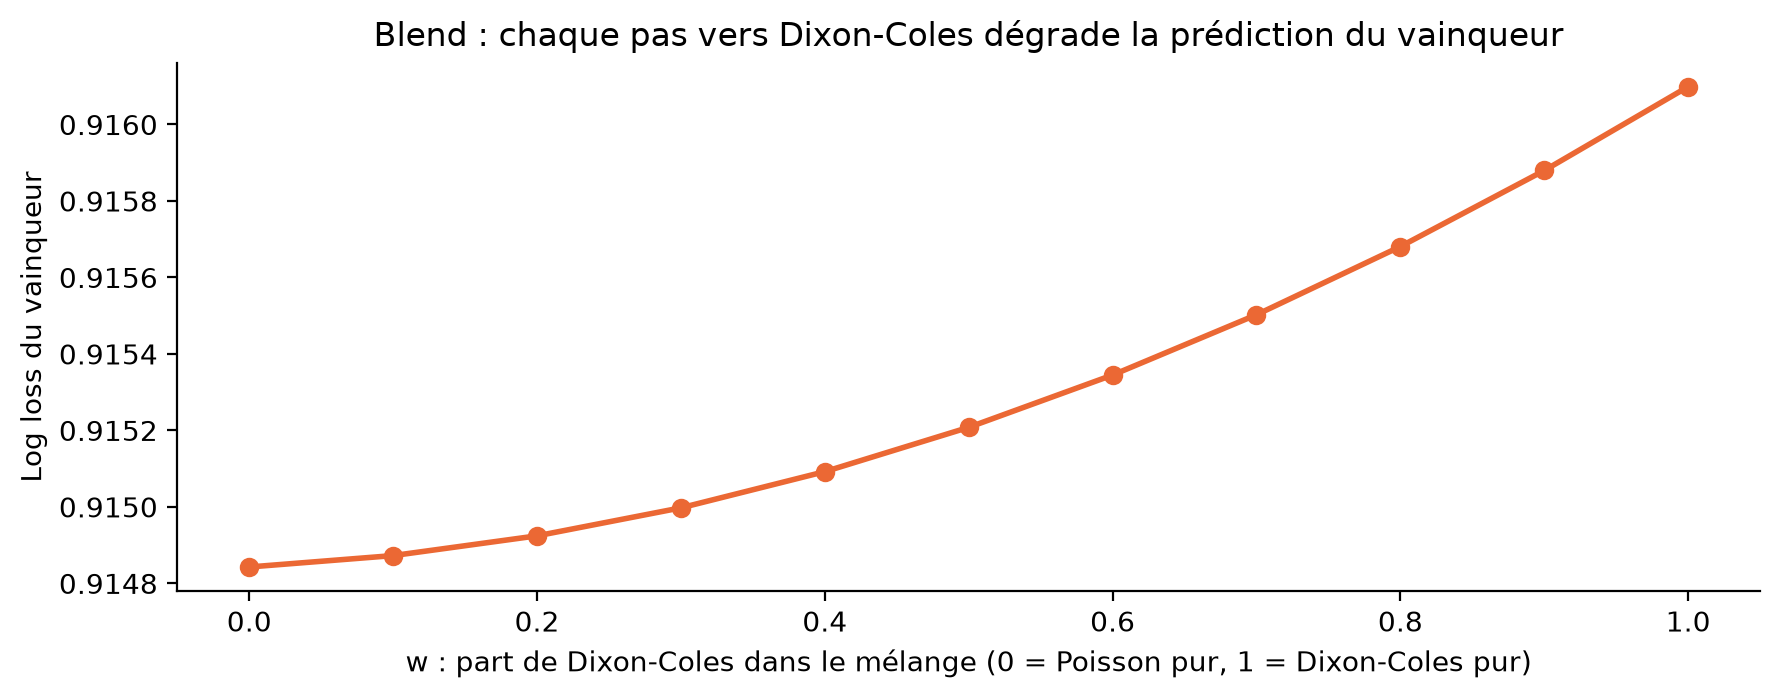

Blend honnête (2016-2022) : 0.9184 | Poisson simple : 0.9175


,w choisi sur le passé,blend,Poisson simple
saison,,,
2016,0.0,0.9059,0.9059
2017,1.0,0.9539,0.9514
2018,0.9,0.9427,0.9405
2019,0.4,0.9086,0.9072
2020,0.0,0.8974,0.8974
2021,0.0,0.9206,0.9206
2022,0.0,0.8995,0.8995


In [16]:
blend = pd.DataFrame(lignes_blend)
courbe = blend.groupby('w').apply(lambda t: moyenne_ponderee(t, ['log loss du vainqueur', 'log loss des scores']))

honnete = []
for saison in list(SAISONS_VALIDATION)[1:]:
    passe = blend[blend['saison'] < saison].groupby('w').apply(lambda t: np.average(t['log loss du vainqueur'], weights=t['matchs']))
    w = passe.idxmin()
    honnete.append({'saison': saison, 'w choisi sur le passé': w,
                    'blend': blend[(blend['saison'] == saison) & np.isclose(blend['w'], w)]['log loss du vainqueur'].iloc[0],
                    'Poisson simple': par_saison_pistes.loc[saison, REFERENCE]})
honnete = pd.DataFrame(honnete).set_index('saison')

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(courbe.index, courbe['log loss du vainqueur'], marker='o', color=ORANGE, linewidth=2)
ax.set_xlabel('w : part de Dixon-Coles dans le mélange (0 = Poisson pur, 1 = Dixon-Coles pur)')
ax.set_ylabel('Log loss du vainqueur')
ax.set_title('Blend : chaque pas vers Dixon-Coles dégrade la prédiction du vainqueur')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Blend honnête (2016-2022) : {honnete['blend'].mean():.4f} | Poisson simple : {honnete['Poisson simple'].mean():.4f}")
honnete.round(4)

**Deux vérifications vers l'avant.**
1. **Dixon-Coles dans le nouveau format.** Sur 2015-2022, tout est dans l'ancien format. Or on observe moins de nuls depuis 2024 (section 7) : un ρ unique mélange deux époques. On teste donc aussi **un ρ par format**, en apprenant jusqu'en 2024-2025 et en prédisant 2025-2026, avec la variable « nouveau format ».
2. **La confirmation du fine-tuning qui passe la règle**, une seule fois, sur le test 2023-2025.

In [17]:
# 1. Dixon-Coles vers l'avant : apprendre jusqu'en 2024-2025, prédire 2025-2026
VARIABLES_FORMAT = VARIABLES + ['nouveau_format']
grilles_25 = {'Poisson + format (notre modèle)': predire_poisson(appr_25, saison_25, VARIABLES_FORMAT)[3]}
grilles_25['Dixon-Coles, un seul rho'], info_1 = predire_dixon_coles(appr_25, saison_25, VARIABLES_FORMAT)
grilles_25['Dixon-Coles, un rho par format'], info_2 = predire_dixon_coles(appr_25, saison_25, VARIABLES_FORMAT, par_format=True)
print("rho :", {k: round(v, 3) for k, v in {**info_1, **info_2}.items()})

ref_v, ref_s, _ = pertes_grilles(grilles_25['Poisson + format (notre modèle)'], d25)
lignes_25 = []
for nom, m in grilles_25.items():
    v, sc, nuls = pertes_grilles(m, d25)
    ligne = {'modèle': nom, 'log loss du vainqueur': v.mean(), 'log loss des scores': sc.mean(), 'nuls prévus': nuls.mean(),
             '0-0 prévus': m[:, 0, 0].mean(), '1-1 prévus': m[:, 1, 1].mean()}
    if nom != 'Poisson + format (notre modèle)':
        bas, haut = intervalle(ref_v - v)
        ligne['gain sur le vainqueur (IC 95 %)'] = f"{(ref_v - v).mean():+.4f} ({bas:+.4f} à {haut:+.4f})"
    lignes_25.append(ligne)
print(f"Réel 2025-2026 : nuls {(d25['resultat'] == 'Nul').mean():.1%}, "
      f"0-0 {((d25['buts_dom'] == 0) & (d25['buts_ext'] == 0)).mean():.1%}, 1-1 {((d25['buts_dom'] == 1) & (d25['buts_ext'] == 1)).mean():.1%}")
display(pd.DataFrame(lignes_25).set_index('modèle').style.format(
    {'log loss du vainqueur': '{:.4f}', 'log loss des scores': '{:.4f}', 'nuls prévus': '{:.1%}', '0-0 prévus': '{:.1%}', '1-1 prévus': '{:.1%}'},
    na_rep='—'))

# 2. Confirmation, une seule fois, du fine-tuning « écart d'Elo au carré » sur le test 2023-2025
base_v, _, _ = pertes_grilles(predire_poisson(avant_test, test)[3], g[test])
carre_v, _, _ = pertes_grilles(predire_poisson(avant_test, test, VARIABLES + ['ecart2_100'])[3], g[test])
coef_carre = coefficients(entrainer_poisson(g[avant_test], VARIABLES + ['ecart2_100']), VARIABLES + ['ecart2_100'])['ecart2_100']
bas, haut = intervalle(base_v - carre_v)
print(f"\nÉcart d'Elo au carré — coefficient {coef_carre:+.4f} ; gain sur le test 2023-2025 : "
      f"{(base_v - carre_v).mean():+.4f} (intervalle à 95 % : {bas:+.4f} à {haut:+.4f})")

rho : {'rho': np.float64(-0.048), 'rho ancien format': np.float64(-0.077), 'rho nouveau format': np.float64(0.117)}
Réel 2025-2026 : nuls 17.6%, 0-0 5.3%, 1-1 5.3%


,log loss du vainqueur,log loss des scores,nuls prévus,0-0 prévus,1-1 prévus,gain sur le vainqueur (IC 95 %)
modèle,,,,,,
Poisson + format (notre modèle),0.9304,3.2728,20.0%,4.0%,9.2%,—
"Dixon-Coles, un seul rho",0.9325,3.2719,20.9%,4.4%,9.6%,-0.0021 (-0.0051 à +0.0011)
"Dixon-Coles, un rho par format",0.9276,3.2807,17.9%,2.9%,8.1%,+0.0028 (-0.0052 à +0.0104)



Écart d'Elo au carré — coefficient -0.0039 ; gain sur le test 2023-2025 : +0.0002 (intervalle à 95 % : -0.0006 à +0.0010)


**Lecture :**
**1. Dixon-Coles dans le nouveau format (2025-2026, 188 matchs) :**

| | Vainqueur | Scores | Nuls (17,6 % réels) | 0-0 (5,3 % réels) | 1-1 (5,3 % réels) | Gain sur le vainqueur |
|---|---|---|---|---|---|---|
| Poisson + format (notre modèle) | 0,9304 | **3,2728** | 20,0 % | 4,0 % | 9,2 % | — |
| Dixon-Coles, un seul ρ (−0,048) | 0,9325 | **3,2719** | 20,9 % | 4,4 % | 9,6 % | −0,002, non démontré |
| Dixon-Coles, un ρ par format (−0,077 / **+0,117**) | **0,9276** | 3,2807 | **17,9 %** | 2,9 % | 8,1 % | +0,003, non démontré |

- **Le ρ du nouveau format est positif** (+0,117), à l'inverse de l'ancien : depuis 2024, on observe **moins** de petits scores que le Poisson ne le prévoit. C'est la même observation qu'en section 7 (moins de nuls), vue autrement.
- **Avec un ρ par format, les nuls sont presque parfaits** (17,9 % prévus, 17,6 % réels), et c'est la seule variante qui prédit mieux le vainqueur que notre modèle. **Mais** elle retire trop de 0-0 (2,9 % au lieu de 5,3 %), donc les scores exacts sont moins bien prévus. Et son gain n'est pas démontré : l'intervalle contient 0, sur 188 matchs seulement.
- **Ce ρ est instable** : appris sur la seule saison 2024-2025 (13,8 % de nuls, une valeur extrême), il vaut +0,117 ; appris sur les deux saisons du nouveau format, il tombe à +0,037. On ne peut pas s'appuyer dessus aujourd'hui.

**2. La confirmation du terme en écart d'Elo au carré, sur le test 2023-2025 :** un gain de +0,0002, avec un intervalle de −0,0006 à +0,0010 qui contient 0. **Le test ne le confirme pas.** Son coefficient (−0,004) est d'ailleurs à peine différent de 0 : les matchs très déséquilibrés auraient à peine moins de buts que ce que prévoit le modèle linéaire.

**Décision :** on garde le **Poisson simple**. Aucune piste ne le bat de façon démontrée, et chacune ajouterait de la complexité : un paramètre de plus, des fonctions d'export à changer, et une simulation à relancer. La plus prometteuse, Dixon-Coles avec un ρ par format, est gardée comme **prochaine expérience**, à réévaluer quand les matchs 2026-2027 seront disponibles.

## 10. De nouvelles informations : forces d'attaque et de défense, joueurs récents

Jusqu'ici, le modèle ne connaît le niveau d'une équipe que par **un seul nombre**, l'Elo. `v2_forces.ipynb` construit deux informations nouvelles, connues avant chaque match :

| Variable | Ce qu'elle mesure | Comment (sans information future) |
|---|---|---|
| **Forces d'attaque et de défense** (`force_ad`) | combien une équipe **devrait** marquer contre cet adversaire : attaque(équipe) + défense(adversaire) | un modèle de Poisson appris chaque mois sur **tous** les matchs de clubs de `games.csv` des 3 années précédentes (environ 18 000), soit 1 700 clubs |
| **Valeur des joueurs récents** (`valeur_recente`) | la valeur des 11 joueurs les plus utilisés lors des 5 derniers matchs, donc une approximation des blessures et des rotations | `appearances.csv` et `player_valuations.csv`, strictement avant le match |

**Le réglage des forces** (la longueur de la mémoire et le poids des vieux matchs) a été choisi **en validation glissante seulement**, parmi 18 combinaisons, avec le modèle « Elo + forces + terrain » :

| Mémoire | Demi-vie 120 jours | Demi-vie 240 jours | Demi-vie 480 jours |
|---|---|---|---|
| 1 an | 0,9153 | 0,9156 | 0,9157 |
| 2 ans | 0,9143 | 0,9132 | 0,9126 |
| **3 ans** | 0,9143 | 0,9131 | **0,9123** |

(log loss de la validation glissante, pénalité de 10⁻⁴ ; une pénalité de 10⁻³ fait moins bien partout). Le réglage retenu, 3 ans et 480 jours, est celui de `v2_forces.ipynb`. On peut refaire cette grille en changeant les réglages en tête de ce notebook.

**Le protocole :** on compare 7 variantes en validation glissante. **La règle, la même que pour la forme récente :** une variante doit améliorer la log loss moyenne **et** faire mieux sur au moins 5 saisons sur 8. Parmi celles qui passent, on garde **la meilleure log loss**. Puis on la vérifie **une seule fois** sur le test, et sur 2025-2026 avec la variable « format ».

In [18]:
VARIANTES_10 = {
    'A. Elo + terrain (sections 2 à 9)': VARIABLES,
    "B. + valeur de l'effectif": VARIABLES + ['valeur_effectif'],
    'C. + valeur des joueurs récents': VARIABLES + ['valeur_recente'],
    "D. + forces d'attaque/défense": VARIABLES + ['force_ad'],
    "E. + forces + valeur de l'effectif": VARIABLES + ['force_ad', 'valeur_effectif'],
    'F. + forces + valeur des joueurs récents': VARIABLES + ['force_ad', 'valeur_recente'],
    'G. + forces + les deux valeurs': VARIABLES + ['force_ad', 'valeur_effectif', 'valeur_recente'],
}
lignes_10 = []
for nom, variables in VARIANTES_10.items():
    for saison in SAISONS_VALIDATION:
        appr, a_predire = g['season'] < saison, g['season'] == saison
        lignes_10.append({'variante': nom, 'saison': saison, 'matchs': a_predire.sum(),
                          **mesures(g.loc[a_predire, 'resultat'], predire_poisson(appr, a_predire, variables)[0])})
v10 = pd.DataFrame(lignes_10)
bilan_10 = v10.groupby('variante').apply(lambda t: pd.Series({c: np.average(t[c], weights=t['matchs'])
                                                              for c in ['log loss', 'RPS', 'accuracy', 'balanced accuracy']}))
piv_10 = v10.pivot(index='saison', columns='variante', values='log loss')
REF_10 = 'A. Elo + terrain (sections 2 à 9)'
nb_10 = {n: (piv_10[n] < piv_10[REF_10] - 1e-6).sum() for n in bilan_10.index}
passe_10 = {n: n != REF_10 and bilan_10.loc[n, 'log loss'] < bilan_10.loc[REF_10, 'log loss'] - 1e-6 and nb_10[n] >= 5
            for n in bilan_10.index}
bilan_10['saisons meilleures'] = ['—' if n == REF_10 else f"{nb_10[n]} / 8" for n in bilan_10.index]
bilan_10['passe la règle ?'] = ['—' if n == REF_10 else ('oui' if passe_10[n] else 'non') for n in bilan_10.index]
CHOIX_10 = bilan_10[[passe_10[n] for n in bilan_10.index]]['log loss'].idxmin()
print(f"Variante choisie en validation : {CHOIX_10}")
bilan_10.style.format({'log loss': '{:.4f}', 'RPS': '{:.4f}', 'accuracy': '{:.1%}', 'balanced accuracy': '{:.1%}'})

Variante choisie en validation : F. + forces + valeur des joueurs récents


,log loss,RPS,accuracy,balanced accuracy,saisons meilleures,passe la règle ?
variante,,,,,,
A. Elo + terrain (sections 2 à 9),0.9148,0.1869,59.1%,48.9%,—,—
B. + valeur de l'effectif,0.9162,0.1869,59.3%,49.1%,5 / 8,non
C. + valeur des joueurs récents,0.9119,0.1858,59.0%,48.8%,6 / 8,oui
D. + forces d'attaque/défense,0.9123,0.1863,58.9%,48.7%,4 / 8,non
E. + forces + valeur de l'effectif,0.9137,0.1863,59.2%,48.9%,5 / 8,oui
F. + forces + valeur des joueurs récents,0.9097,0.1853,59.7%,49.3%,5 / 8,oui
G. + forces + les deux valeurs,0.9114,0.1857,59.7%,49.3%,6 / 8,oui


**Lecture :**
| Validation glissante (994 matchs) | Log loss | Accuracy | Saisons meilleures | Règle |
|---|---|---|---|---|
| A. Elo + terrain | 0,9148 | 59,1 % | — | — |
| B. + valeur de l'effectif | 0,9162 | 59,3 % | 5 / 8 | non |
| C. + valeur des joueurs récents | 0,9119 | 59,0 % | 6 / 8 | passe |
| D. + forces d'attaque/défense | 0,9123 | 58,9 % | 4 / 8 | non |
| E. + forces + valeur de l'effectif | 0,9137 | 59,2 % | 5 / 8 | passe |
| **F. + forces + valeur des joueurs récents** | **0,9097** | **59,7 %** | 5 / 8 | **passe, la meilleure** |
| G. + forces + les deux valeurs | 0,9114 | 59,7 % | 6 / 8 | passe |

- **Les deux informations nouvelles se complètent.** Seules, elles aident un peu, ou pas assez souvent (D ne passe pas la règle). Ensemble (F), elles donnent la meilleure log loss de tout le notebook : 0,9097 contre 0,9148.
- **La valeur des joueurs récents remplace avantageusement la valeur de l'effectif** : B ne passe pas la règle, et ajouter la valeur de l'effectif à F (G) fait moins bien. Ce qui compte, ce n'est pas ce que vaut tout l'effectif, mais **ce que valent les joueurs qui jouent vraiment en ce moment**.
- **Le choix est fait par la règle, sans regarder le test.** Une autre variante (E) faisait légèrement mieux sur le test lors d'un premier essai : la choisir pour cette raison serait tricher.
- **La limite :** le gain est petit et inégal selon les saisons. Les forces sont moins précises dans les premières saisons (2015 à 2018), où la mémoire de 3 ans de `games.csv`, qui commence en 2012, n'est pas encore remplie.

**La vérification, une seule fois, sur le test 2023-2025**, avec un bootstrap apparié comme en section 5. Puis **2025-2026**, en apprenant jusqu'en 2024-2025 avec la variable « format » : c'est la configuration du modèle final.

In [19]:
VARIABLES_CHOIX = VARIANTES_10[CHOIX_10]

# 1. Test 2023-2025 (apprentissage 2012-2022)
p_a, la_d, la_e, m_a = predire_poisson(avant_test, test)
p_c, lc_d, lc_e, m_c = predire_poisson(avant_test, test, VARIABLES_CHOIX)
y_num = y_test.map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
perte = lambda p: -np.log(p[ISSUES].to_numpy()[np.arange(len(y_num)), y_num])
juste = lambda p: p[ISSUES].to_numpy().argmax(axis=1) == y_num
gain_ll, gain_acc = perte(p_a) - perte(p_c), juste(p_c).astype(int) - juste(p_a).astype(int)
ic_ll, ic_acc = intervalle(gain_ll), intervalle(gain_acc)
test_10 = pd.DataFrame({'Elo + terrain': mesures(y_test, p_a), CHOIX_10: mesures(y_test, p_c)}).T
print(f"Test 2023-2025 : {juste(p_a).sum()} puis {juste(p_c).sum()} matchs bien prédits sur {len(y_num)} "
      f"({(juste(p_c) & ~juste(p_a)).sum()} gagnés, {(~juste(p_c) & juste(p_a)).sum()} perdus)")
print(f"Gain de log loss : {gain_ll.mean():+.4f} (intervalle à 95 % : {ic_ll[0]:+.4f} à {ic_ll[1]:+.4f})")
print(f"Gain d'accuracy : {gain_acc.mean():+.1%} (intervalle à 95 % : {ic_acc[0]:+.1%} à {ic_acc[1]:+.1%})")
for saison in [2023, 2024, 2025]:
    k = (g.loc[test, 'season'] == saison).to_numpy()
    print(f"  {saison}-{saison + 1} : accuracy {juste(p_a)[k].mean():.1%} → {juste(p_c)[k].mean():.1%}")
display(test_10.style.format({'log loss': '{:.4f}', 'RPS': '{:.4f}', 'accuracy': '{:.1%}', 'balanced accuracy': '{:.1%}'}))

# 2. 2025-2026, avec la variable « format » (la configuration du modèle final)
i_, j_ = np.meshgrid(K, K, indexing='ij')
lignes_25 = {}
for nom, variables in [('Elo + terrain + format', VARIABLES + ['nouveau_format']),
                       (CHOIX_10 + ' + format', VARIABLES_CHOIX + ['nouveau_format'])]:
    p25, l_d, l_e, m25 = predire_poisson(appr_25, saison_25, variables)
    lignes_25[nom] = {**mesures(d25['resultat'], p25), 'log loss des buts': log_loss_buts(l_d, l_e, d25),
                      'buts prévus': (l_d + l_e).mean(), '5 buts ou plus prévus': m25[:, (i_ + j_) >= 5].sum(axis=1).mean()}
reel_25 = d25['buts_dom'] + d25['buts_ext']
print(f"\n2025-2026 ({saison_25.sum()} matchs) — réel : {reel_25.mean():.2f} buts par match, {(reel_25 >= 5).mean():.1%} de matchs à 5 buts ou plus")
pd.DataFrame(lignes_25).T.style.format({'log loss': '{:.4f}', 'RPS': '{:.4f}', 'accuracy': '{:.1%}', 'balanced accuracy': '{:.1%}',
                                        'log loss des buts': '{:.4f}', 'buts prévus': '{:.2f}', '5 buts ou plus prévus': '{:.1%}'})

Test 2023-2025 : 294 puis 303 matchs bien prédits sur 502 (16 gagnés, 7 perdus)
Gain de log loss : +0.0098 (intervalle à 95 % : +0.0015 à +0.0181)
Gain d'accuracy : +1.8% (intervalle à 95 % : +0.0% à +3.8%)
  2023-2024 : accuracy 60.0% → 62.4%
  2024-2025 : accuracy 57.7% → 58.7%
  2025-2026 : accuracy 58.5% → 60.6%


,log loss,RPS,accuracy,balanced accuracy
Elo + terrain,0.9023,0.1932,58.6%,45.5%
F. + forces + valeur des joueurs récents,0.8925,0.1908,60.4%,47.2%



2025-2026 (188 matchs) — réel : 3.47 buts par match, 29.8% de matchs à 5 buts ou plus


,log loss,RPS,accuracy,balanced accuracy,log loss des buts,buts prévus,5 buts ou plus prévus
Elo + terrain + format,0.9304,0.1996,58.5%,45.5%,3.2730,3.27,23.3%
F. + forces + valeur des joueurs récents + format,0.9203,0.1980,60.1%,47.2%,3.2452,3.23,22.7%


**Lecture :**
| | Accuracy | Log loss |
|---|---|---|
| **Test 2023-2025**, Elo + terrain | 58,6 % (294 matchs) | 0,9023 |
| **Test 2023-2025**, variante F | **60,4 %** (303 matchs) | **0,8925** |
| **2025-2026**, Elo + terrain + format | 58,5 % | 0,9304 |
| **2025-2026**, F + format (le modèle final) | **60,1 %** | **0,9203** |

- **Le test confirme la validation** : 9 matchs de plus bien prédits (16 gagnés, 7 perdus), et un gain **sur chacune des 3 saisons** (62,4 %, 58,7 % et 60,6 %).
- **Le gain est réel sur la qualité des probabilités** : +0,0098 de log loss, avec un intervalle à 95 % de +0,0015 à +0,0181, entièrement au-dessus de 0.
- **Le gain d'accuracy est à la limite du démontrable** : +1,8 point, avec un intervalle de 0,0 à +3,8 points. Sur 502 matchs, une accuracy n'est connue qu'à ± 4 points près. C'est pour ça qu'on choisit avec la log loss.
- **Sur 2025-2026, la configuration finale fait mieux partout** : le vainqueur (0,9203 contre 0,9304), les scores (log loss des buts de 3,245 contre 3,273) et l'accuracy (60,1 % contre 58,5 %).
- **Le défaut restant, ce sont les gros scores** : 3,23 buts prévus par match pour 3,47 réels, et 22,7 % de matchs à 5 buts ou plus prévus pour 29,8 % réels. On marque de plus en plus (3,27 buts par match en 2024-2025, 3,47 en 2025-2026), et le modèle a toujours une saison de retard.

**Et les gros scores ?** Le modèle prévoit un peu trop peu de matchs à 5 buts ou plus. Une piste classique est la **loi binomiale négative**, qui autorise plus de variabilité que la loi de Poisson. On estime sa dispersion sur l'apprentissage, puis on compare sur 2025-2026.

In [20]:
from scipy.stats import nbinom

variables_f = VARIABLES_CHOIX + ['nouveau_format']
modele_25 = entrainer_poisson(g[appr_25], variables_f)
lignes_appr_25 = lignes_equipes(g[appr_25])
mu_appr = modele_25.predict(lignes_appr_25[variables_f])
surdispersion = (((lignes_appr_25['buts'] - mu_appr) ** 2 - mu_appr) / mu_appr ** 2).mean()
r = 1 / surdispersion                                  # variance = moyenne + moyenne² / r
l_d, l_e = buts_attendus_matchs(modele_25, d25, variables_f)
grille_bn = nbinom.pmf(K[None, :, None], r, r / (r + l_d[:, None, None])) * nbinom.pmf(K[None, None, :], r, r / (r + l_e[:, None, None]))
grille_bn /= grille_bn.sum(axis=(1, 2), keepdims=True)
v_p, s_p, _ = pertes_grilles(matrices_scores(l_d, l_e), d25)
v_b, s_b, _ = pertes_grilles(grille_bn, d25)
print(f"Dispersion estimée : r = {r:.0f} (plus r est grand, plus on est proche de Poisson)")
pd.DataFrame({'log loss du vainqueur': [v_p.mean(), v_b.mean()], 'log loss des scores': [s_p.mean(), s_b.mean()],
              '5 buts ou plus prévus': [matrices_scores(l_d, l_e)[:, (i_ + j_) >= 5].sum(axis=1).mean(),
                                        grille_bn[:, (i_ + j_) >= 5].sum(axis=1).mean()]},
             index=['Poisson', 'binomiale négative']).style.format(
    {'log loss du vainqueur': '{:.4f}', 'log loss des scores': '{:.4f}', '5 buts ou plus prévus': '{:.1%}'})

Dispersion estimée : r = 37 (plus r est grand, plus on est proche de Poisson)


,log loss du vainqueur,log loss des scores,5 buts ou plus prévus
Poisson,0.9203,3.2450,22.7%
binomiale négative,0.9197,3.2423,23.0%


**Lecture :**
- **La dispersion est faible** (r = 37) : les buts sont presque exactement poissoniens, comme le montrait déjà la section 2 (dispersion de 1,05).
- **Le gain est minuscule** : 0,0006 sur le vainqueur et 0,003 sur les scores, et les matchs à 5 buts ou plus passent seulement de 22,7 % à 23,0 % (29,8 % réels). Sur le test 2023-2025, la même correction faisait même un peu moins bien sur le vainqueur.
- **Décision :** on garde la loi de Poisson. La binomiale négative ne corrige pas le manque de gros scores, qui vient de la hausse du nombre de buts d'une saison à l'autre, pas de la forme de la loi. Elle compliquerait toutes les fonctions d'export pour un gain invisible.

### 10 bis. Face aux bookmakers

**La comparaison la plus exigeante possible.** Battre un Dummy est facile. La vraie référence, ce sont les **bookmakers**, qui connaissent tout ce que notre modèle ignore : blessures, compositions, transferts, motivation. Leurs **cotes de clôture**, juste avant le coup d'envoi, sont le meilleur prédicteur qui existe.

**Les données :** le jeu Kaggle « Football Odds Movements 2018-2026, 4 Bookmakers » (dossier `data/cotes_c1/`, fichiers `matches.csv` et `match_closing.csv`), avec les cotes de clôture de Pinnacle, Bet365, SBOBET et Singbet pour 1 807 matchs de C1 (qualifications comprises), de 2018 à 2026. On les relie à nos matchs par la date, à un jour près, et par les noms des équipes. On transforme ensuite les cotes en probabilités, en retirant la marge du bookmaker.

**Trois questions :**
1. Notre modèle fait-il aussi bien que les bookmakers ?
2. Mélanger notre modèle et les cotes fait-il mieux ? Le poids du mélange est choisi sur 2018-2022, puis vérifié sur le test.
3. Qu'en conclure sur le plafond d'accuracy atteignable ?

Si le dossier `data/cotes_c1/` n'existe pas, cette section est sautée sans erreur.

In [21]:
import re, unicodedata
from difflib import SequenceMatcher

DOSSIER_COTES = '../data/cotes_c1'
COTES_DISPONIBLES = os.path.exists(f'{DOSSIER_COTES}/matches.csv') and os.path.exists(f'{DOSSIER_COTES}/match_closing.csv')

def mots(nom):
    nom = unicodedata.normalize('NFKD', str(nom)).encode('ascii', 'ignore').decode().lower()
    nom = re.sub(r'\b(fc|cf|ac|as|sc|ssc|afc|sv|vfb|vfl|fk|sk|bv|rc|rb|ud|cd|club|de|des|the|1907|1909|1899|04|05)\b', ' ', nom)
    return re.sub(r'[^a-z ]', ' ', nom).split()

def ressemblance(a, b):
    # 1 = même club ; combine les mots communs et la ressemblance des chaînes
    ma, mb = mots(a), mots(b)
    if not ma or not mb:
        return 0.0
    return max(len(set(ma) & set(mb)) / min(len(set(ma)), len(set(mb))), SequenceMatcher(None, ' '.join(ma), ' '.join(mb)).ratio())

if COTES_DISPONIBLES:
    matchs_cotes = pd.read_csv(f'{DOSSIER_COTES}/matches.csv', parse_dates=['kickoff_utc'])
    matchs_cotes = matchs_cotes[matchs_cotes['league_name'] == 'UEFA Champions League'].copy()
    matchs_cotes['jour'] = matchs_cotes['kickoff_utc'].dt.tz_convert('Europe/Paris').dt.tz_localize(None).dt.normalize()
    cloture = pd.read_csv(f'{DOSSIER_COTES}/match_closing.csv')
    cloture = cloture[cloture['match_id'].isin(matchs_cotes['match_id'])].dropna(subset=['close_1x2_home', 'close_1x2_draw', 'close_1x2_away'])

    liens = []
    for _, r in g[g['season'] >= 2018].iterrows():
        candidats = matchs_cotes[(matchs_cotes['jour'] - r['date']).abs() <= pd.Timedelta(days=1)]
        if candidats.empty:
            continue
        score = candidats.apply(lambda c: ressemblance(r['home_club_name'], c['home_team'])
                                + ressemblance(r['away_club_name'], c['away_team']), axis=1)
        if score.max() >= 1.0:
            c = candidats.loc[score.idxmax()]
            liens.append({'game_id': r['game_id'], 'match_id': c['match_id'],
                          'meme_score': (c['ft_home'] == r['buts_dom']) and (c['ft_away'] == r['buts_ext'])})
    liens = pd.DataFrame(liens)

    def probas_bookmaker(nom):
        c = cloture[cloture['bookmaker'] == nom].set_index('match_id')[['close_1x2_home', 'close_1x2_draw', 'close_1x2_away']]
        inverse = 1 / c
        p = inverse.div(inverse.sum(axis=1), axis=0)              # marge du bookmaker retirée
        p.columns = ISSUES
        return liens.set_index('game_id')['match_id'].map(lambda m: m).to_frame().join(p, on='match_id')[ISSUES]

    bookmakers = {nom: probas_bookmaker(nom) for nom in ['Pinnacle', 'Bet365']}
    print(f"Matchs de C1 de 2018 à 2025 chez nous : {(g['season'] >= 2018).sum()} | reliés aux cotes : {len(liens)} "
          f"| même score dans les deux fichiers : {liens['meme_score'].mean():.1%}")
else:
    print(f"{DOSSIER_COTES} n'existe pas : section sautée (télécharger le jeu Kaggle pour la refaire).")

Matchs de C1 de 2018 à 2025 chez nous : 1121 | reliés aux cotes : 1117 | même score dans les deux fichiers : 99.2%


Poids du mélange choisi sur 2018-2022 : 0% de notre modèle, 100% de Pinnacle
Test 2023-2025, log loss du modèle − log loss de Pinnacle : +0.0018 (intervalle à 95 % : -0.0133 à +0.0168)


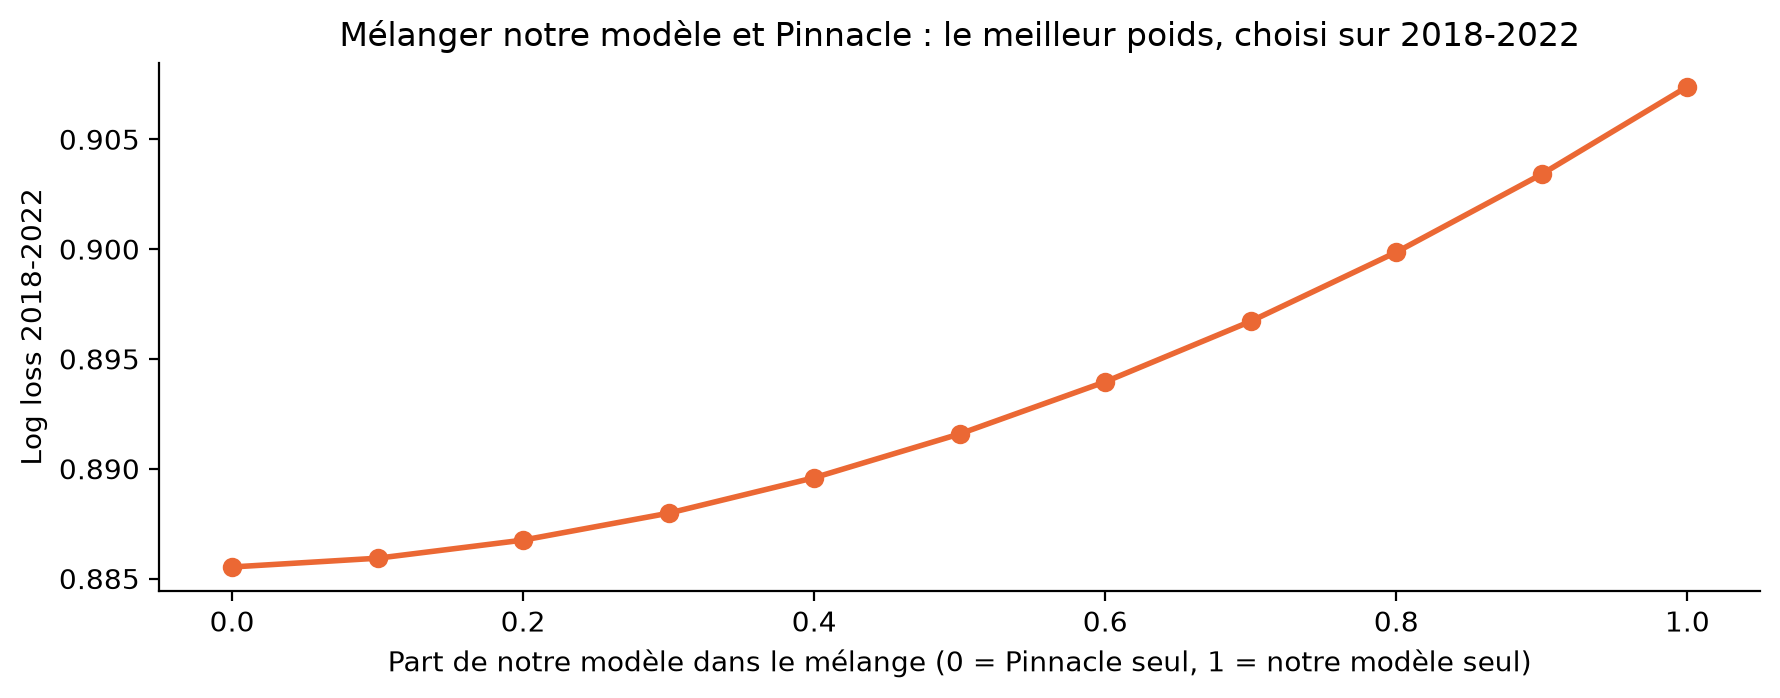

In [22]:
if COTES_DISPONIBLES:
    # Les probabilités « hors échantillon » de notre modèle : validation glissante pour 2018-2022, test pour 2023-2025
    morceaux = []
    for saison in range(2018, 2023):
        appr, a_predire = g['season'] < saison, g['season'] == saison
        morceaux.append(predire_poisson(appr, a_predire, VARIABLES_CHOIX)[0].set_index(g.loc[a_predire, 'game_id'].to_numpy()))
    morceaux.append(predire_poisson(avant_test, test, VARIABLES_CHOIX)[0].set_index(g.loc[test, 'game_id'].to_numpy()))
    p_modele = pd.concat(morceaux)

    communs = p_modele.index.intersection(bookmakers['Pinnacle'].dropna().index)
    resultat = g.set_index('game_id').loc[communs, 'resultat']
    saison_de = g.set_index('game_id').loc[communs, 'season']
    periodes = {'2018-2022 (validation)': saison_de <= 2022, '2023-2025 (test)': saison_de >= 2023}

    # Le poids du mélange : choisi sur 2018-2022 seulement
    k_val = periodes['2018-2022 (validation)']
    poids = np.round(np.linspace(0, 1, 11), 1)
    ll_poids = [mesures(resultat[k_val], w * p_modele.loc[communs][k_val] + (1 - w) * bookmakers['Pinnacle'].loc[communs][k_val])['log loss']
                for w in poids]
    W = poids[int(np.argmin(ll_poids))]

    lignes_b = []
    for nom_p, k in periodes.items():
        sources = {'Notre modèle (section 10)': p_modele.loc[communs][k],
                   'Pinnacle': bookmakers['Pinnacle'].loc[communs][k], 'Bet365': bookmakers['Bet365'].loc[communs][k],
                   f'Mélange ({W:.0%} modèle)': W * p_modele.loc[communs][k] + (1 - W) * bookmakers['Pinnacle'].loc[communs][k]}
        for nom_s, p in sources.items():
            ok = p.notna().all(axis=1)
            lignes_b.append({'période': nom_p, 'source': nom_s, 'matchs': ok.sum(), **mesures(resultat[k][ok], p[ok])})
    face = pd.DataFrame(lignes_b).set_index(['période', 'source'])

    # Le modèle et Pinnacle sur le test : l'écart est-il réel ?
    k_t = periodes['2023-2025 (test)']
    y_t = resultat[k_t].map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
    perte_m = -np.log(p_modele.loc[communs][k_t][ISSUES].to_numpy()[np.arange(k_t.sum()), y_t])
    perte_b = -np.log(bookmakers['Pinnacle'].loc[communs][k_t][ISSUES].to_numpy()[np.arange(k_t.sum()), y_t])
    bas, haut = intervalle(perte_m - perte_b)
    print(f"Poids du mélange choisi sur 2018-2022 : {W:.0%} de notre modèle, {1 - W:.0%} de Pinnacle")
    print(f"Test 2023-2025, log loss du modèle − log loss de Pinnacle : {(perte_m - perte_b).mean():+.4f} "
          f"(intervalle à 95 % : {bas:+.4f} à {haut:+.4f})")

    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(poids, ll_poids, marker='o', color=ORANGE, linewidth=2)
    ax.set_xlabel('Part de notre modèle dans le mélange (0 = Pinnacle seul, 1 = notre modèle seul)')
    ax.set_ylabel('Log loss 2018-2022')
    ax.set_title('Mélanger notre modèle et Pinnacle : le meilleur poids, choisi sur 2018-2022')
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()
    display(face.style.format({'log loss': '{:.4f}', 'RPS': '{:.4f}', 'accuracy': '{:.1%}', 'balanced accuracy': '{:.1%}'}))

**Lecture :**
| | 2018-2022 : accuracy | 2018-2022 : log loss | **2023-2025 (test) : accuracy** | 2023-2025 : log loss |
|---|---|---|---|---|
| **Notre modèle** | 60,2 % | 0,9074 | **60,4 %** (303 matchs) | 0,8925 |
| **Pinnacle** | 62,6 % | 0,8855 | 60,2 % (302 matchs) | 0,8907 |
| Bet365 | 62,5 % | 0,8834 | 60,4 % | 0,8920 |
| Meilleur mélange (100 % Pinnacle) | 62,6 % | 0,8855 | 60,2 % | 0,8907 |

- **Les données sont fiables** : 1 117 matchs sur 1 121 sont reliés aux cotes, et 99,2 % ont le même score dans les deux fichiers.
- **Sur le test 2023-2025, notre modèle fait jeu égal avec les bookmakers.** 303 bons résultats contre 302 pour Pinnacle, et un écart de log loss de +0,002, avec un intervalle de −0,013 à +0,017 qui contient 0. Pour un modèle qui ne connaît ni les blessures ni les compositions, c'est remarquable.
- **Sur 2018-2022, les bookmakers étaient nettement meilleurs** (62,6 % contre 60,2 %). Notre modèle a rattrapé son retard sur les saisons récentes : ce sont celles où les forces d'attaque et de défense disposent de 3 années d'historique complètes.
- **Mélanger notre modèle et les cotes n'apporte rien.** Le meilleur poids, choisi sur 2018-2022, est « 100 % Pinnacle » : notre modèle n'ajoute rien à ce que savent déjà les bookmakers. Sur le test, ce mélange fait 60,2 %.
- **La conclusion la plus importante : 60 % est le plafond.** Même les meilleurs professionnels, avec toute leur information, ne font pas mieux sur 2023-2025. Au-delà, c'est le hasard du football : un poteau, un penalty, un carton rouge.
- **Et les cotes ne servent qu'à la veille d'un match.** Elles n'existent pas pour les matchs de mars ou de mai quand on simule la saison en septembre. Notre modèle, lui, le peut.

## 11. Le modèle final et ce qu'il a appris

Le modèle est validé. On l'entraîne maintenant sur **toutes les saisons** (2012-2026), test compris, pour qu'il profite des 1 871 matchs, avec la variante choisie en section 10 et la variable « nouveau format ». C'est cette version qui sert pour 2026-2027.

Buts attendus entre deux équipes de même niveau, sur terrain neutre, nouveau format : 1.59
Nouveau format : buts attendus × 1.127 (IC 95 % : × 1.059 à × 1.199)
+100 points d'Elo d'avance : buts attendus × 1.101 (IC 95 % : × 1.070 à × 1.132)
Recevoir plutôt que jouer sur terrain neutre : buts attendus × 1.138
Recevoir plutôt que se déplacer : buts attendus × 1.295
Forces d'attaque/défense : 1 point de log en plus (buts « attendus » × 2,7) → buts × 1.554
Joueurs récents deux fois plus chers que ceux de l'adversaire : buts × 1.038


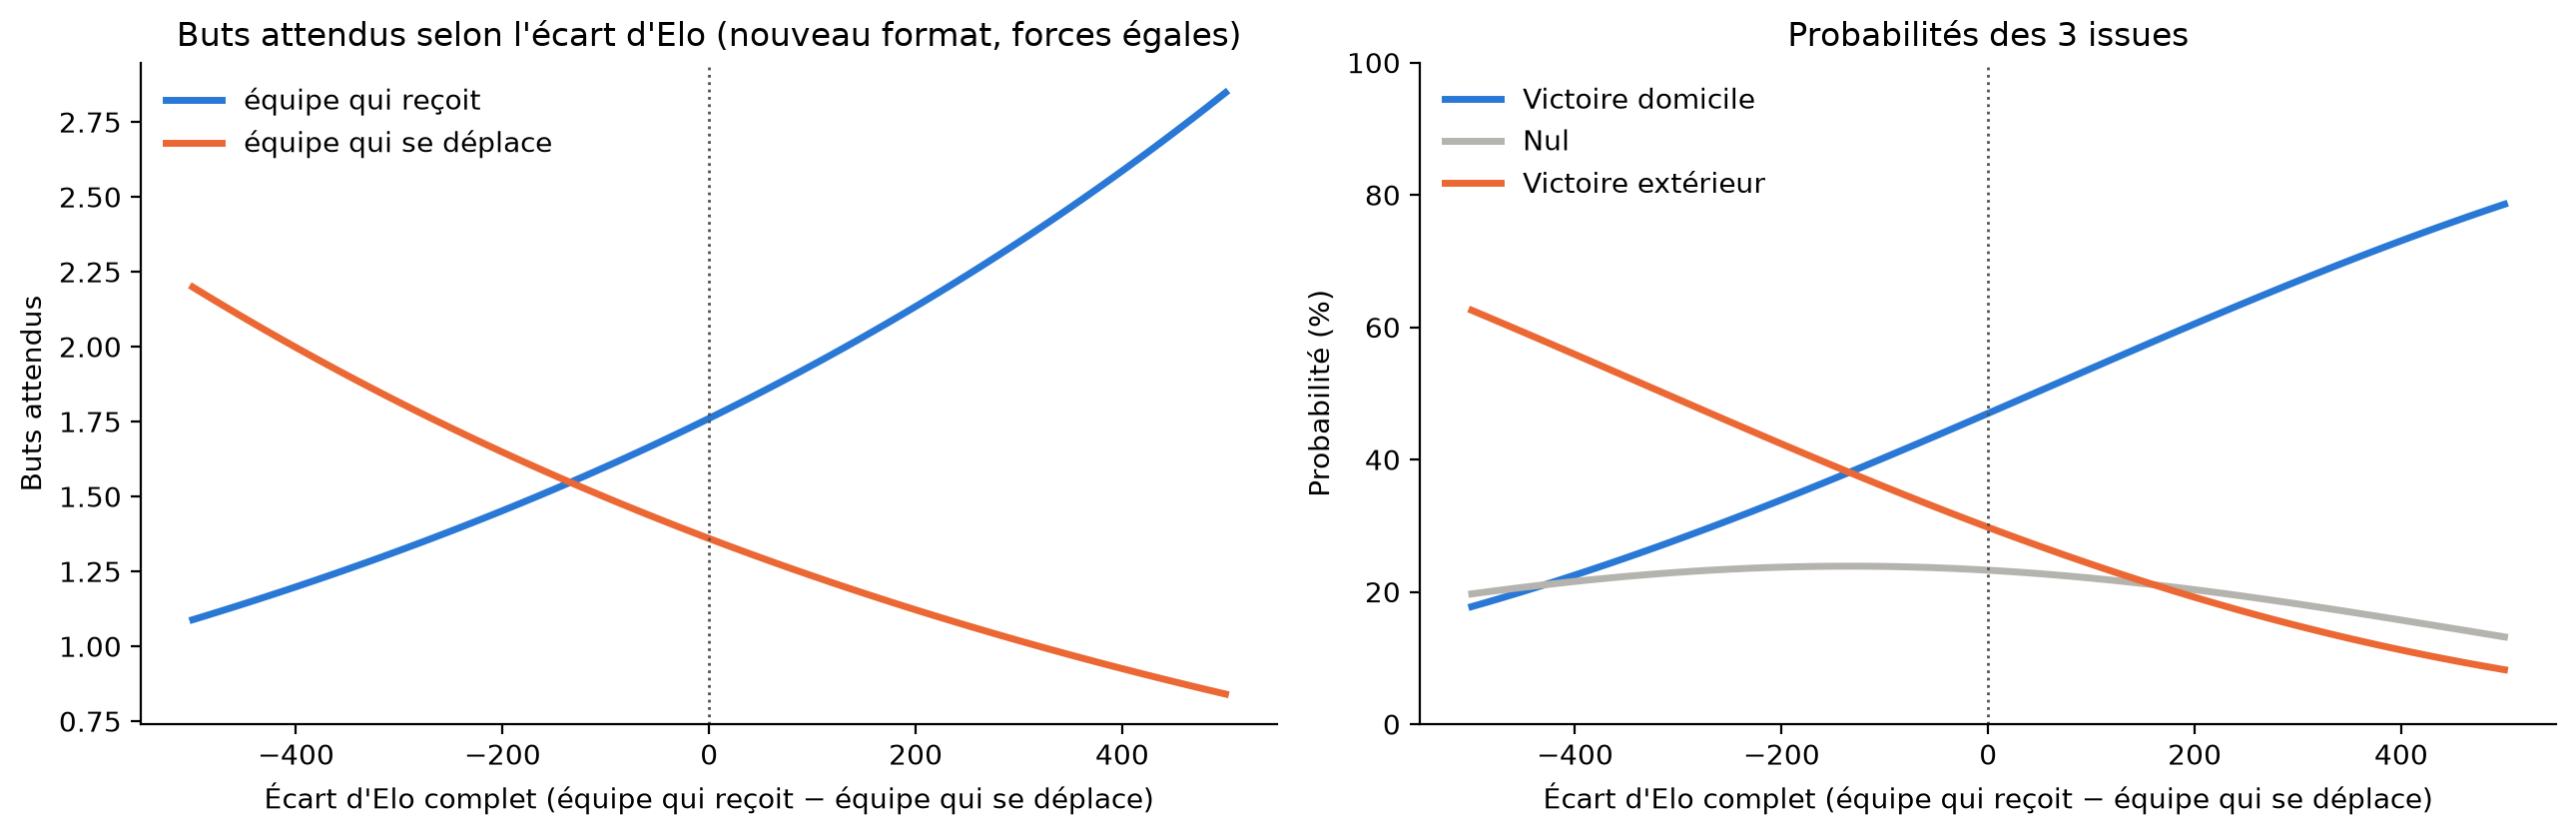

,coefficient,IC 95 % bas,IC 95 % haut
constante,0.3460,0.3141,0.3780
écart d'Elo (par 100 points),0.0962,0.0681,0.1242
terrain,0.1293,0.1031,0.1555
forces d'attaque/défense,0.4406,0.3233,0.5579
valeur des joueurs récents (écart de log),0.0531,0.0297,0.0766
nouveau format,0.1194,0.0570,0.1818


In [23]:
VARIABLES_FINALES = VARIABLES_CHOIX + ['nouveau_format']
if garder_forme:
    print("⚠️ La forme récente améliore le modèle : il faudra l'ajouter à l'export, et la simulation devra la calculer.")
final = entrainer_poisson(g, VARIABLES_FINALES)
coefs = coefficients(final, VARIABLES_FINALES)

# Les intervalles de confiance viennent de statsmodels, qui ajuste exactement le même modèle
lignes_tout = lignes_equipes(g)
verification = sm.GLM(lignes_tout['buts'], sm.add_constant(lignes_tout[VARIABLES_FINALES]),
                      family=sm.families.Poisson()).fit()
assert np.allclose(verification.params[coefs.index], coefs, atol=1e-4), "scikit-learn et statsmodels ne trouvent pas le même modèle"
ic = verification.conf_int()

lecture = pd.DataFrame({
    'coefficient': coefs, 'IC 95 % bas': ic[0], 'IC 95 % haut': ic[1],
}).rename(index={'const': 'constante', 'ecart_100': 'écart d\'Elo (par 100 points)', 'terrain': 'terrain',
                 'nouveau_format': 'nouveau format', 'force_ad': "forces d'attaque/défense",
                 'valeur_recente': 'valeur des joueurs récents (écart de log)', 'valeur_effectif': "valeur de l'effectif (écart de log)"})
print(f"Buts attendus entre deux équipes de même niveau, sur terrain neutre, nouveau format : "
      f"{np.exp(coefs['const'] + coefs['nouveau_format']):.2f}")
print(f"Nouveau format : buts attendus × {np.exp(coefs['nouveau_format']):.3f} "
      f"(IC 95 % : × {np.exp(ic.loc['nouveau_format', 0]):.3f} à × {np.exp(ic.loc['nouveau_format', 1]):.3f})")
print(f"+100 points d'Elo d'avance : buts attendus × {np.exp(coefs['ecart_100']):.3f} "
      f"(IC 95 % : × {np.exp(ic.loc['ecart_100', 0]):.3f} à × {np.exp(ic.loc['ecart_100', 1]):.3f})")
print(f"Recevoir plutôt que jouer sur terrain neutre : buts attendus × {np.exp(coefs['terrain']):.3f}")
print(f"Recevoir plutôt que se déplacer : buts attendus × {np.exp(2 * coefs['terrain']):.3f}")
if 'force_ad' in coefs:
    print(f"Forces d'attaque/défense : 1 point de log en plus (buts « attendus » × 2,7) → buts × {np.exp(coefs['force_ad']):.3f}")
if 'valeur_recente' in coefs:
    print(f"Joueurs récents deux fois plus chers que ceux de l'adversaire : buts × {np.exp(coefs['valeur_recente'] * np.log(2)):.3f}")

# Ce que le modèle a appris, selon l'écart d'Elo
ecarts = np.arange(-500, 501, 10, dtype=float)
grille = pd.DataFrame({'ecart_elo_complet': ecarts, 'domicile': 1, 'nouveau_format': 1,
                       'force_ad_dom': g['force_ad_dom'].median(), 'force_ad_ext': g['force_ad_dom'].median(),
                       'ecart_valeur_recente': 0.0})          # deux équipes aux forces et aux effectifs comparables
l_d, l_e = buts_attendus_matchs(final, grille, VARIABLES_FINALES)
p_grille = issues_depuis_scores(matrices_scores(l_d, l_e))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.plot(ecarts, l_d, color=BLEU, linewidth=2.5, label='équipe qui reçoit')
ax1.plot(ecarts, l_e, color=ORANGE, linewidth=2.5, label='équipe qui se déplace')
ax1.set_ylabel('Buts attendus')
ax1.set_title('Buts attendus selon l\'écart d\'Elo (nouveau format, forces égales)')
for issue, couleur in zip(ISSUES, [BLEU, GRIS, ORANGE]):
    ax2.plot(ecarts, p_grille[issue] * 100, color=couleur, linewidth=2.5, label=issue)
ax2.set_ylabel('Probabilité (%)')
ax2.set_ylim(0, 100)
ax2.set_title('Probabilités des 3 issues')
for ax in (ax1, ax2):
    ax.axvline(0, color=ENCRE, linewidth=1, linestyle=':')
    ax.set_xlabel("Écart d'Elo complet (équipe qui reçoit − équipe qui se déplace)")
    ax.legend(frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
lecture.round(4)

**Lecture :**
| Ce que le modèle a appris (1 871 matchs) | Effet sur les buts attendus | Intervalle à 95 % |
|---|---|---|
| +100 points d'Elo d'avance | **× 1,10** (+10 %) | × 1,07 à × 1,13 |
| Forces d'attaque/défense : +1 point de log | **× 1,55** | × 1,38 à × 1,75 |
| Joueurs récents deux fois plus chers que ceux de l'adversaire | × 1,04 | × 1,02 à × 1,05 |
| Recevoir plutôt que se déplacer | **× 1,29** (+29 %) | — |
| Nouveau format | **× 1,13** (+13 %) | × 1,06 à × 1,20 |

- **L'Elo pèse deux fois moins qu'avant** (× 1,10 pour 100 points, contre × 1,22 dans le modèle Elo + terrain) : une partie de ce qu'il mesurait est maintenant portée par les forces d'attaque et de défense, plus précises sur **comment** une équipe gagne.
- **Les forces d'attaque et de défense sont prises avec prudence** : quand elles annoncent 2,7 fois plus de buts (+1 point de log), le modèle n'en retient que × 1,55. C'est logique : elles sont apprises surtout en championnat, contre d'autres adversaires qu'en C1.
- **Les trois intervalles des nouvelles variables sont entièrement au-dessus de 1** : leur effet est net.
- **Deux équipes de même niveau, sur terrain neutre, dans le nouveau format, marquent 1,59 but chacune.**
- **Le nul plafonne toujours vers 24 %** quand les deux équipes sont proches.

## 12. Export pour l'application et la simulation

On sauvegarde les **coefficients** (des nombres), pas l'objet Python : l'application et la simulation n'ont besoin que de `numpy`.

Quatre fonctions, à copier telles quelles :

| Fonction | Ce qu'elle renvoie | Pour qui |
|---|---|---|
| `entrees_match(forces, club_dom, club_ext)` | les 3 nouvelles entrées d'un match, à partir de `output/forces_participants_2026.csv` | tout le monde |
| `buts_attendus(p, ecart_elo, domicile, minutes, **entrees)` | les buts attendus des deux équipes | tout le monde |
| `matrice_scores(p, ecart_elo, domicile, minutes, **entrees)` | la probabilité de chaque score, de 0-0 à 10-10 | l'application |
| `probas_match(p, ecart_elo, domicile, **entrees)` | victoire, nul, défaite | l'application |
| `tirer_score(p, ecart_elo, domicile, minutes, rng, **entrees)` | un score tiré au hasard, par exemple (2, 1) | la simulation |

**Ce qui change par rapport à la version précédente :** chaque fonction prend en plus les entrées du match (`force_ad_dom`, `force_ad_ext`, `ecart_valeur_recente`), données par `entrees_match`. L'écart d'Elo reste à part, car la simulation le met à jour après chaque match ; les forces et les effectifs, eux, restent ceux du 8 septembre 2026. Sans ces entrées, les fonctions prennent des valeurs moyennes, utiles pour un test rapide seulement.

**Conventions :** `ecart_elo` = Elo complet de l'équipe qui reçoit − Elo complet de l'autre ; `domicile = 1` si elle reçoit vraiment, `0` sur terrain neutre (la finale). `minutes = 30` donne les buts attendus d'une **prolongation** (le modèle répartit les buts uniformément sur le match). `nouveau_format = 1` par défaut : c'est le cas de toutes les saisons depuis 2024-2025.

In [24]:
parametres = {
    'type': 'poisson',
    'intercept': float(coefs['const']),
    'coef_ecart_100': float(coefs['ecart_100']),
    'coef_terrain': float(coefs['terrain']),
    'coef_nouveau_format': float(coefs['nouveau_format']),
    'coef_force_ad': float(coefs.get('force_ad', 0.0)),
    'coef_valeur_recente': float(coefs.get('valeur_recente', 0.0)),
    'mediane_force_ad': float(np.median(lignes_equipes(g)['force_ad'])),   # valeur par défaut si une entrée manque
    'max_buts': MAX_BUTS,
    'issues': ISSUES,
    'variables': VARIABLES_FINALES,
    'entraine_sur': f"{g['season'].min()}-{g['season'].max()} ({len(g)} matchs)",
}

def entrees_match(forces, club_dom, club_ext):
    # forces : output/forces_participants_2026.csv indexé par club_id (colonnes attaque, defense, valeur_recente_eur)
    a, b = forces.loc[club_dom], forces.loc[club_ext]
    return {'force_ad_dom': float(a['attaque'] + b['defense']), 'force_ad_ext': float(b['attaque'] + a['defense']),
            'ecart_valeur_recente': float(np.log(a['valeur_recente_eur']) - np.log(b['valeur_recente_eur']))}

def buts_attendus(p, ecart_elo, domicile=1, minutes=90, nouveau_format=1,
                  force_ad_dom=None, force_ad_ext=None, ecart_valeur_recente=0.0):
    # Buts attendus (équipe qui reçoit, équipe qui se déplace)
    f_dom = p['mediane_force_ad'] if force_ad_dom is None else force_ad_dom
    f_ext = p['mediane_force_ad'] if force_ad_ext is None else force_ad_ext
    niveau = p['intercept'] + p['coef_nouveau_format'] * nouveau_format
    z = p['coef_ecart_100'] * ecart_elo / 100 + p['coef_terrain'] * domicile + p['coef_valeur_recente'] * ecart_valeur_recente
    duree = minutes / 90
    return (float(np.exp(niveau + z + p['coef_force_ad'] * f_dom) * duree),
            float(np.exp(niveau - z + p['coef_force_ad'] * f_ext) * duree))

def matrice_scores(p, ecart_elo, domicile=1, minutes=90, **entrees):
    # m[i, j] = probabilité que l'équipe qui reçoit marque i buts et l'autre j
    l_dom, l_ext = buts_attendus(p, ecart_elo, domicile, minutes, **entrees)
    k = np.arange(p['max_buts'] + 1)
    fact = np.array([factorial(n) for n in k], dtype=float)
    m = np.outer(np.exp(-l_dom) * l_dom ** k / fact, np.exp(-l_ext) * l_ext ** k / fact)
    return m / m.sum()

def probas_match(p, ecart_elo, domicile=1, **entrees):
    m = matrice_scores(p, ecart_elo, domicile, **entrees)
    return {'Victoire domicile': float(np.tril(m, -1).sum()), 'Nul': float(np.trace(m)),
            'Victoire extérieur': float(np.triu(m, 1).sum())}

def tirer_score(p, ecart_elo, domicile=1, minutes=90, rng=None, **entrees):
    rng = rng if rng is not None else np.random.default_rng()
    l_dom, l_ext = buts_attendus(p, ecart_elo, domicile, minutes, **entrees)
    return int(rng.poisson(l_dom)), int(rng.poisson(l_ext))

# Vérifications
verif = pd.DataFrame({'ecart_elo_complet': [250.0, -120.0, 0.0], 'domicile': [1, 1, 0], 'nouveau_format': [1, 1, 1],
                      'force_ad_dom': [0.6, -0.2, 0.1], 'force_ad_ext': [-0.4, 0.3, 0.1], 'ecart_valeur_recente': [1.2, -0.5, 0.0]})
attendu = issues_depuis_scores(matrices_scores(*buts_attendus_matchs(final, verif, VARIABLES_FINALES)))
for k, ligne in verif.iterrows():
    obtenu = probas_match(parametres, ligne['ecart_elo_complet'], ligne['domicile'], force_ad_dom=ligne['force_ad_dom'],
                          force_ad_ext=ligne['force_ad_ext'], ecart_valeur_recente=ligne['ecart_valeur_recente'])
    assert all(abs(obtenu[i] - attendu.loc[k, i]) < 1e-9 for i in ISSUES)
    assert abs(sum(obtenu.values()) - 1) < 1e-12
rng = np.random.default_rng(GRAINE)
exemple_entrees = {'force_ad_dom': 0.6, 'force_ad_ext': -0.4, 'ecart_valeur_recente': 1.2}
tirages = np.array([tirer_score(parametres, 250.0, 1, rng=rng, **exemple_entrees) for _ in range(100_000)])
assert np.allclose(tirages.mean(axis=0), buts_attendus(parametres, 250.0, 1, **exemple_entrees), atol=0.02)
l90, l30 = buts_attendus(parametres, 0, 0), buts_attendus(parametres, 0, 0, minutes=30)
assert abs(l30[0] - l90[0] / 3) < 1e-12

os.makedirs('../output', exist_ok=True)
joblib.dump(parametres, '../output/modele_scores.joblib')
print("Vérifications OK. Modèle sauvegardé : output/modele_scores.joblib")
print(f"Exemple, +250 d'Elo à domicile : {buts_attendus(parametres, 250.0, 1)[0]:.2f} – "
      f"{buts_attendus(parametres, 250.0, 1)[1]:.2f} buts attendus, "
      + ', '.join(f"{i} {v:.1%}" for i, v in probas_match(parametres, 250.0, 1).items()))

Vérifications OK. Modèle sauvegardé : output/modele_scores.joblib
Exemple, +250 d'Elo à domicile : 2.24 – 1.07 buts attendus, Victoire domicile 63.8%, Nul 19.3%, Victoire extérieur 16.9%


## 13. Prédictions de la phase de ligue 2026-2027

On applique le modèle final aux **144 matchs officiels** de la phase de ligue (calendrier de `v2_participants.ipynb`), avec l'Elo complet des 36 clubs **avant le 8 septembre 2026**. Les résultats déjà joués ne sont pas utilisés : c'est une prévision faite avant le début de la compétition.

Pour chaque match : les buts attendus, le score le plus probable et les 3 probabilités. Le fichier `output/predictions_phase_ligue_2026.csv` sert à l'application et sert de point de départ à la simulation.

In [25]:
calendrier = pd.read_csv('../output/calendrier_2026.csv', encoding='utf-8-sig', parse_dates=['date'])
elo = pd.read_csv('../output/elo_participants_2026.csv').set_index('club_id')['elo_complet']
forces_2026 = pd.read_csv('../output/forces_participants_2026.csv', encoding='utf-8-sig').set_index('club_id')
assert forces_2026.index.equals(forces_2026.index.unique()) and set(elo.index) <= set(forces_2026.index)

matchs = (calendrier[calendrier['lieu'] == 'domicile']
          .rename(columns={'nom_uefa': 'domicile_nom', 'adversaire_uefa': 'exterieur_nom'})
          [['match_id', 'journee', 'date', 'domicile_club_id', 'domicile_nom', 'exterieur_club_id', 'exterieur_nom']]
          .sort_values(['journee', 'match_id']).reset_index(drop=True))
assert len(matchs) == 144 and matchs[['domicile_club_id', 'exterieur_club_id']].isin(elo.index).all().all()

matchs['elo_domicile'] = matchs['domicile_club_id'].map(elo)
matchs['elo_exterieur'] = matchs['exterieur_club_id'].map(elo)
matchs['ecart_elo'] = matchs['elo_domicile'] - matchs['elo_exterieur']
entrees = pd.DataFrame([entrees_match(forces_2026, a, b) for a, b in zip(matchs['domicile_club_id'], matchs['exterieur_club_id'])])
matchs = pd.concat([matchs, entrees], axis=1)
arguments = lambda r: dict(force_ad_dom=r['force_ad_dom'], force_ad_ext=r['force_ad_ext'], ecart_valeur_recente=r['ecart_valeur_recente'])
lam = pd.DataFrame([buts_attendus(parametres, r['ecart_elo'], 1, **arguments(r)) for _, r in matchs.iterrows()])
matchs['buts_attendus_domicile'], matchs['buts_attendus_exterieur'] = lam[0].to_numpy(), lam[1].to_numpy()
issues = pd.DataFrame([probas_match(parametres, r['ecart_elo'], 1, **arguments(r)) for _, r in matchs.iterrows()])
matchs['p_victoire_domicile'], matchs['p_nul'], matchs['p_victoire_exterieur'] = issues[ISSUES].to_numpy().T
grilles_2026 = [matrice_scores(parametres, r['ecart_elo'], 1, **arguments(r)) for _, r in matchs.iterrows()]
matchs['score_le_plus_probable'] = ['{}-{}'.format(*np.unravel_index(m.argmax(), m.shape)) for m in grilles_2026]
i_g, j_g = np.meshgrid(K, K, indexing='ij')
matchs['p_3_buts_ou_plus'] = [m[(i_g + j_g) >= 3].sum() for m in grilles_2026]
matchs['p_les_deux_marquent'] = [m[1:, 1:].sum() for m in grilles_2026]
assert np.allclose(matchs[['p_victoire_domicile', 'p_nul', 'p_victoire_exterieur']].sum(axis=1), 1)

matchs.to_csv('../output/predictions_phase_ligue_2026.csv', index=False, encoding='utf-8-sig')
print(f"{len(matchs)} matchs prédits : output/predictions_phase_ligue_2026.csv")

affichage = lambda d: (d.assign(match=d['domicile_nom'] + ' – ' + d['exterieur_nom'],
                                buts_attendus=d['buts_attendus_domicile'].round(2).astype(str) + ' – '
                                              + d['buts_attendus_exterieur'].round(2).astype(str))
                        .set_index('match')[['journee', 'buts_attendus', 'score_le_plus_probable',
                                             'p_victoire_domicile', 'p_nul', 'p_victoire_exterieur']])
format_p = {c: '{:.0%}' for c in ['p_victoire_domicile', 'p_nul', 'p_victoire_exterieur']}
print("Les 8 plus grosses affiches (somme des deux Elo) :")
affichage(matchs.assign(s=matchs['elo_domicile'] + matchs['elo_exterieur']).nlargest(8, 's')).style.format(format_p)

144 matchs prédits : output/predictions_phase_ligue_2026.csv
Les 8 plus grosses affiches (somme des deux Elo) :


,journee,buts_attendus,score_le_plus_probable,p_victoire_domicile,p_nul,p_victoire_exterieur
match,,,,,,
Bayern München – Arsenal,3,1.59 – 1.5,1-1,40%,24%,36%
FC Barcelona – Man City,6,1.84 – 1.53,1-1,45%,22%,32%
Arsenal – Real Madrid,6,2.01 – 1.08,2-1,59%,21%,20%
Man City – Paris,2,2.04 – 1.26,2-1,55%,21%,23%
Paris – FC Barcelona,3,1.8 – 1.62,1-1,43%,22%,35%
Real Madrid – Inter,1,1.91 – 1.34,1-1,51%,22%,27%
Arsenal – Borussia Dortmund,5,2.38 – 0.88,2-0,71%,17%,12%
Man United – Bayern München,7,1.57 – 1.9,1-1,32%,22%,46%


**La difficulté du calendrier, club par club.** Deux clubs de même niveau n'ont pas les mêmes chances s'ils n'ont pas les mêmes adversaires. On mesure, pour chaque club :
- l'**Elo moyen de ses 8 adversaires** ;
- ses **points attendus** sur les 8 matchs : la somme, match par match, de 3 × P(victoire) + 1 × P(nul) ;
- l'**effet du tirage** : ses points attendus, moins ceux qu'il aurait obtenus contre 8 adversaires d'un niveau **moyen** (l'Elo moyen des 35 autres clubs), avec les mêmes matchs à domicile et à l'extérieur. Positif = tirage favorable.

Ce n'est pas encore la simulation (qui donnera le classement et les qualifiés), mais c'est un premier contrôle de cohérence.

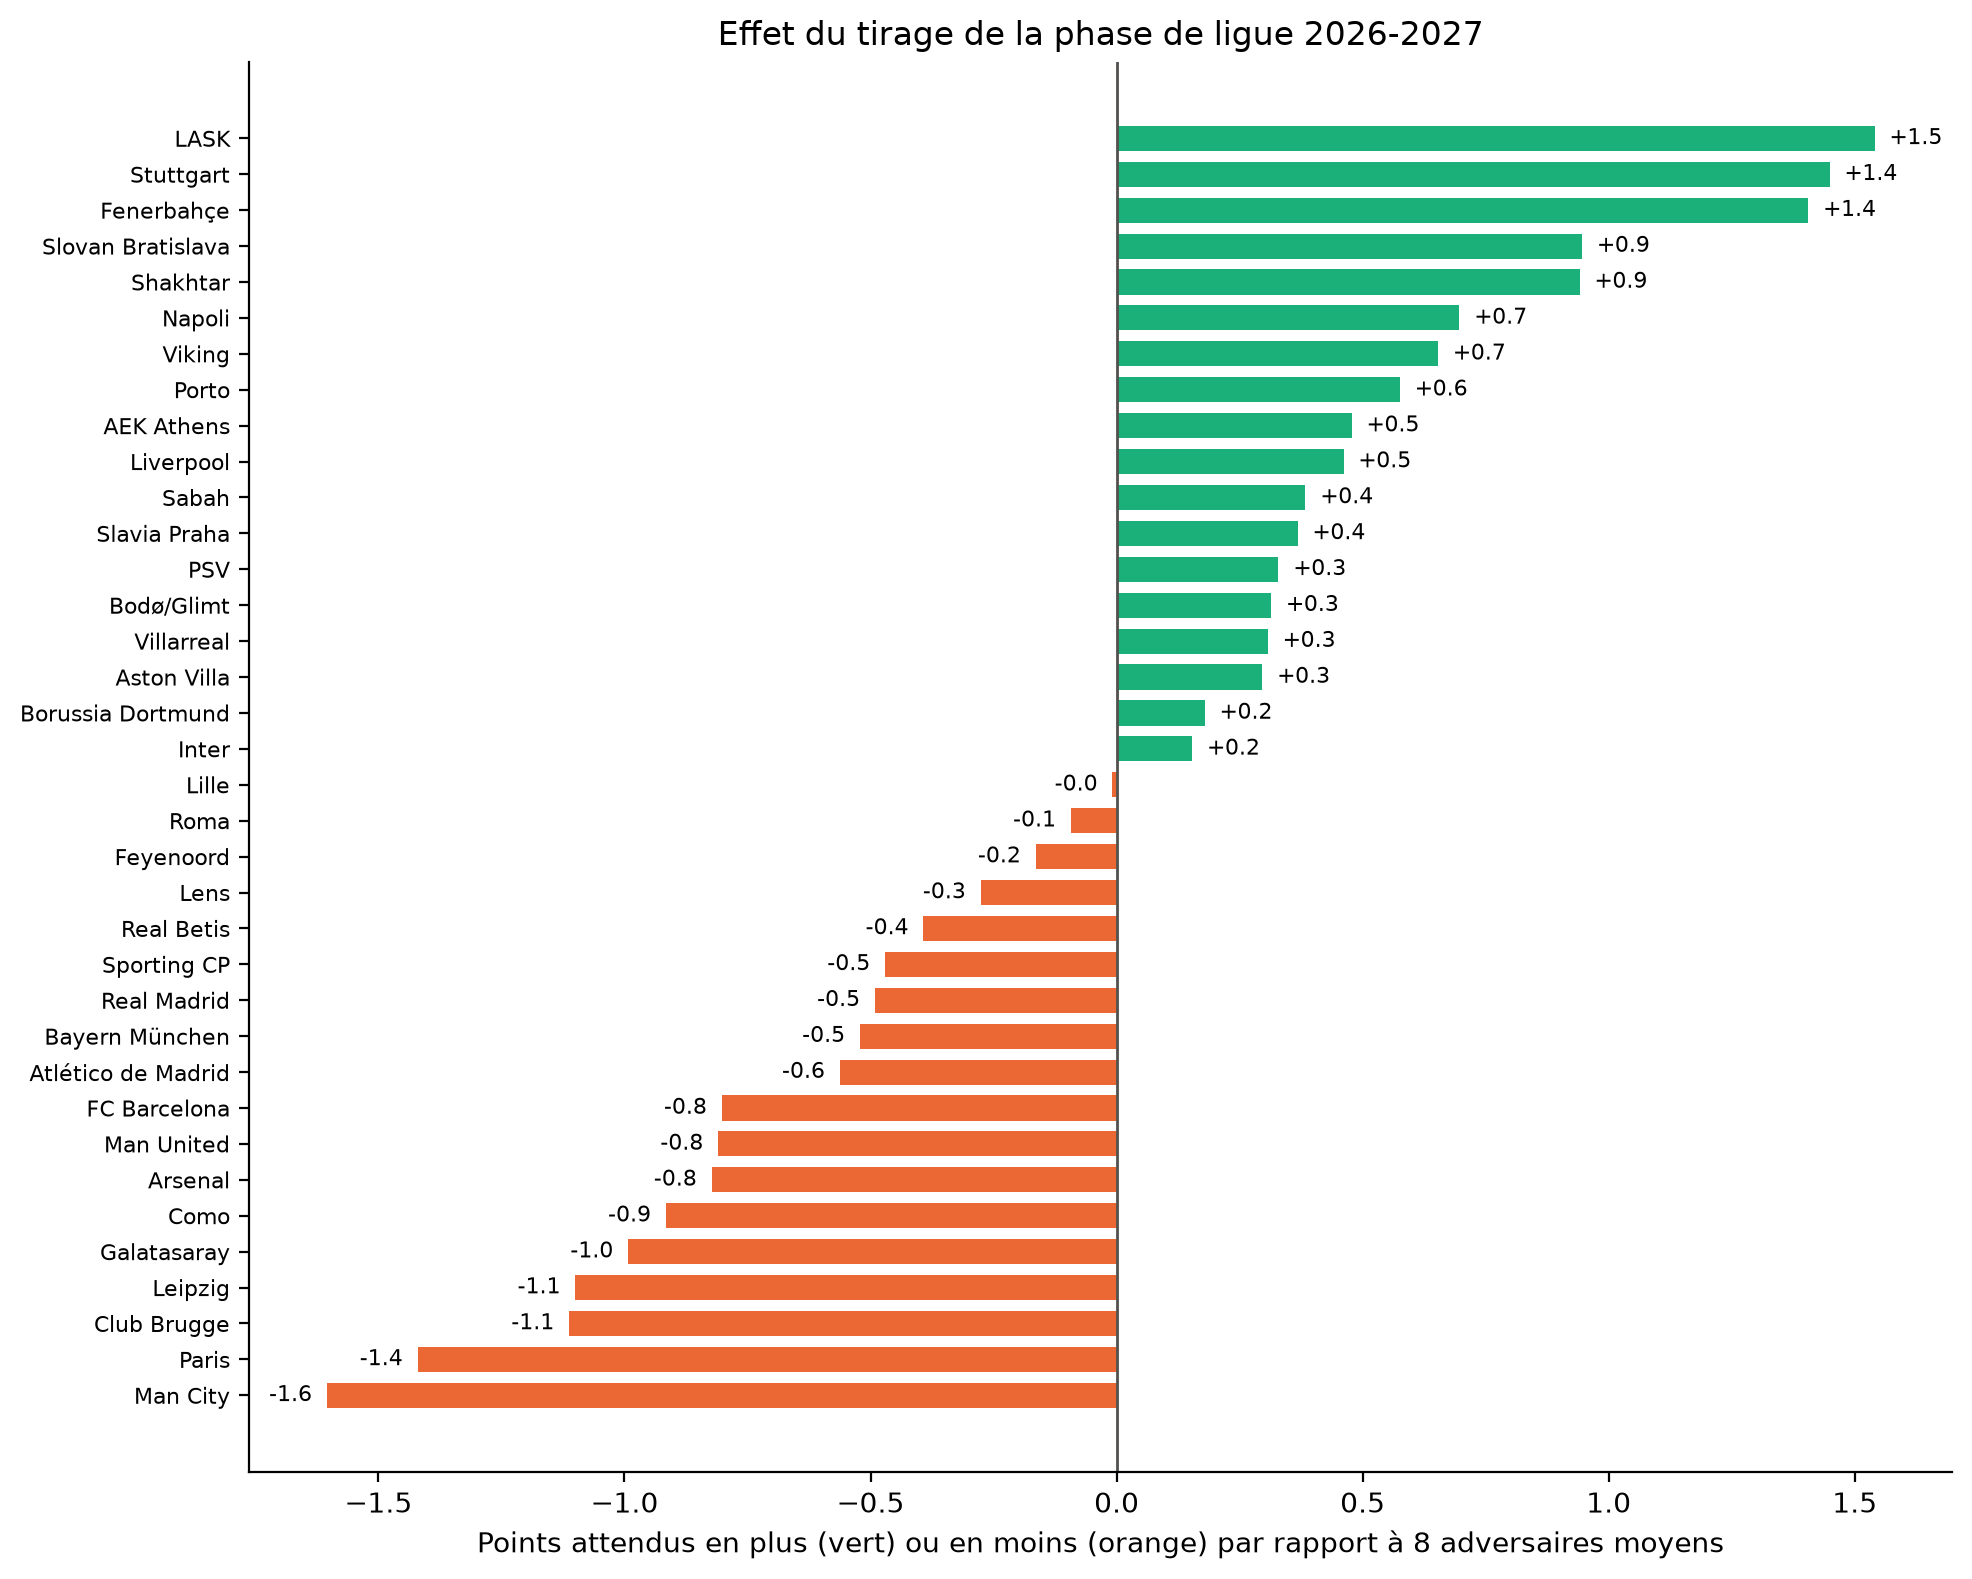

Tirages les plus difficiles : Man City -1.6, Paris -1.4, Club Brugge -1.1
Tirages les plus favorables : LASK +1.5, Stuttgart +1.4, Fenerbahçe +1.4
Buts par match attendus : 3.50 | nuls attendus : 18.6% | 3 buts ou plus : 66.7% | 1-1 comme score le plus probable : 56 matchs sur 144


,rang_points,rang_elo,elo,elo_moyen_adversaires,points_attendus,diff_buts_attendue,effet_tirage
club,,,,,,,
Arsenal,1,1,2025,1765.0,17.8,14.1,-0.8
Bayern München,2,3,1972,1737.0,17.3,12.7,-0.5
FC Barcelona,3,4,1970,1775.0,16.7,11.4,-0.8
Man City,4,2,1989,1804.0,16.2,8.9,-1.6
Liverpool,5,8,1895,1741.0,16.1,8.9,0.5
Real Madrid,6,6,1932,1754.0,16.0,10.1,-0.5
Inter,7,5,1943,1728.0,15.9,9.0,0.2
Paris,8,7,1920,1784.0,14.8,8.2,-1.4
Aston Villa,9,10,1860,1726.0,13.8,4.8,0.3


In [26]:
def points_attendus(p_issues, recoit):
    return 3 * p_issues['Victoire domicile' if recoit else 'Victoire extérieur'] + p_issues['Nul']

vue = pd.concat([
    pd.DataFrame({'club': matchs['domicile_nom'], 'elo': matchs['elo_domicile'], 'elo_adversaire': matchs['elo_exterieur'],
                  'recoit': True, 'points': 3 * matchs['p_victoire_domicile'] + matchs['p_nul'],
                  'buts_pour': matchs['buts_attendus_domicile'], 'buts_contre': matchs['buts_attendus_exterieur']}),
    pd.DataFrame({'club': matchs['exterieur_nom'], 'elo': matchs['elo_exterieur'], 'elo_adversaire': matchs['elo_domicile'],
                  'recoit': False, 'points': 3 * matchs['p_victoire_exterieur'] + matchs['p_nul'],
                  'buts_pour': matchs['buts_attendus_exterieur'], 'buts_contre': matchs['buts_attendus_domicile']}),
])

# Les mêmes 8 matchs (même lieu), mais contre un adversaire moyen : Elo, forces et effectif moyens des 35 autres clubs
nom_vers_id = pd.concat([matchs.set_index('domicile_nom')['domicile_club_id'], matchs.set_index('exterieur_nom')['exterieur_club_id']])
nom_vers_id = nom_vers_id[~nom_vers_id.index.duplicated()]
f26 = forces_2026.loc[elo.index].assign(log_valeur=lambda d: np.log(d['valeur_recente_eur']), elo=elo)
def adversaire_moyen(club_id):
    autres = f26.drop(index=club_id)
    return autres['elo'].mean(), autres['attaque'].mean(), autres['defense'].mean(), autres['log_valeur'].mean()
def points_contre_moyen(club_id, recoit):
    elo_m, att_m, def_m, val_m = adversaire_moyen(club_id)
    c = f26.loc[club_id]
    if recoit:
        e = dict(force_ad_dom=c['attaque'] + def_m, force_ad_ext=att_m + c['defense'], ecart_valeur_recente=c['log_valeur'] - val_m)
        return points_attendus(probas_match(parametres, c['elo'] - elo_m, 1, **e), True)
    e = dict(force_ad_dom=att_m + c['defense'], force_ad_ext=c['attaque'] + def_m, ecart_valeur_recente=val_m - c['log_valeur'])
    return points_attendus(probas_match(parametres, elo_m - c['elo'], 1, **e), False)
vue['points_si_adversaire_moyen'] = [points_contre_moyen(nom_vers_id[club], recoit) for club, recoit in zip(vue['club'], vue['recoit'])]

par_club = vue.groupby('club').agg(elo=('elo', 'first'), elo_moyen_adversaires=('elo_adversaire', 'mean'),
                                   points_attendus=('points', 'sum'), points_si_adversaire_moyen=('points_si_adversaire_moyen', 'sum'),
                                   buts_pour=('buts_pour', 'sum'), buts_contre=('buts_contre', 'sum'), matchs=('points', 'size'))
assert (par_club['matchs'] == 8).all() and len(par_club) == 36
par_club['diff_buts_attendue'] = par_club['buts_pour'] - par_club['buts_contre']
par_club['effet_tirage'] = par_club['points_attendus'] - par_club['points_si_adversaire_moyen']
par_club['rang_elo'] = par_club['elo'].rank(ascending=False).astype(int)
par_club = par_club.sort_values('points_attendus', ascending=False)
par_club['rang_points'] = np.arange(1, 37)

# Graphique : l'effet du tirage, club par club
effet = par_club['effet_tirage'].sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(effet.index, effet, color=[VERT if v > 0 else ORANGE for v in effet], height=0.7)
ax.axvline(0, color=ENCRE, linewidth=1)
for y, v in enumerate(effet):
    ax.text(v + (0.03 if v > 0 else -0.03), y, f"{v:+.1f}", va='center', ha='left' if v > 0 else 'right', fontsize=8)
ax.set_xlabel('Points attendus en plus (vert) ou en moins (orange) par rapport à 8 adversaires moyens')
ax.set_title('Effet du tirage de la phase de ligue 2026-2027')
ax.tick_params(axis='y', labelsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
print("Tirages les plus difficiles :", ', '.join(f"{c} {v:+.1f}" for c, v in effet.head(3).items()))
print("Tirages les plus favorables :", ', '.join(f"{c} {v:+.1f}" for c, v in effet.tail(3).iloc[::-1].items()))
print(f"Buts par match attendus : {(matchs['buts_attendus_domicile'] + matchs['buts_attendus_exterieur']).mean():.2f} | "
      f"nuls attendus : {matchs['p_nul'].mean():.1%} | 3 buts ou plus : {matchs['p_3_buts_ou_plus'].mean():.1%} | "
      f"1-1 comme score le plus probable : {(matchs['score_le_plus_probable'] == '1-1').sum()} matchs sur 144")
par_club[['rang_points', 'rang_elo', 'elo', 'elo_moyen_adversaires', 'points_attendus', 'diff_buts_attendue', 'effet_tirage']] \
    .head(12).round({'elo_moyen_adversaires': 0, 'points_attendus': 1, 'diff_buts_attendue': 1, 'effet_tirage': 1})

**Lecture :**
- **Le modèle attend 3,5 buts par match** sur la phase de ligue, dans la lignée des 3,47 de 2025-2026, **18,6 % de nuls**, et **2 matchs sur 3 à 3 buts ou plus**.
- **Le 1-1 reste le score le plus probable de 56 matchs sur 144**, mais avec seulement 10 % de chances environ à chaque fois. Ce n'est pas une prévision de score : la simulation tire les scores au hasard, et l'application doit montrer plusieurs scores, pas un seul.
- **Exemple, PSG – Barcelone (journée 3) :** 1,80 but attendu contre 1,62. Le modèle donne 43 % de victoire au PSG, 22 % de nul et 35 % au Barça, et **66 % de chances d'avoir 3 buts ou plus**.
- **Arsenal a le plus de points attendus** (17,8), devant le Bayern (17,3) et Barcelone (16,7). **Liverpool remonte** (5e aux points, 8e à l'Elo) grâce à ses forces et à son effectif récent, et **Stuttgart surtout** (12e aux points, 24e à l'Elo), grâce à une très bonne attaque et à un tirage favorable.
- **Le tirage pèse toujours** : Manchester City (−1,6 point) et le PSG (−1,4) ont les plus difficiles ; LASK (+1,5), Stuttgart et Fenerbahçe (+1,4) les plus favorables.
- **Attention à la lecture :** les gros clubs ont presque tous un effet négatif, en partie à cause du système des chapeaux, qui oblige chacun à affronter deux clubs de son propre chapeau.

## 14. Conclusion

### Résultat
**Le modèle final est une régression de Poisson avec l'écart d'Elo, les forces d'attaque et de défense, la valeur des joueurs récents, le terrain et le format.** Il devient le modèle de l'application et de la simulation.

- **Il bat le modèle de départ partout** : en validation (log loss de 0,9097 contre 0,9148), sur le test (**60,4 %** d'accuracy contre 58,6 %, log loss de 0,8925 contre 0,9023, gain significatif) et sur 2025-2026 (**60,1 %** contre 58,5 %).
- **Il a été choisi proprement** : 7 variantes comparées en validation avec une règle fixée à l'avance, le test utilisé une seule fois pour confirmer.
- **Il donne des scores crédibles**, indispensables à la simulation, même s'il sous-estime encore un peu les très gros scores.
- **Il est au niveau des bookmakers sur 2023-2025** (60,4 % contre 60,2 % pour Pinnacle), alors qu'il ne connaît ni les blessures ni les compositions, et qu'il peut simuler toute une saison dès septembre, ce que les cotes ne permettent pas.
- **Il résiste aux pistes proposées par le prof** (section 9) et à la binomiale négative (section 10).
- **Livrables :** `output/modele_scores.joblib` (les coefficients) et `output/predictions_phase_ligue_2026.csv` (les 144 matchs, avec la probabilité de 3 buts ou plus et des deux équipes qui marquent). **Les fonctions changent** : elles prennent en plus les forces et l'écart de valeur de chaque match, donnés par `entrees_match` (section 12). L'application et la simulation doivent être mises à jour.

### Les deux limites principales
1. **Le modèle ne voit les blessures que de loin**, à travers la valeur des joueurs utilisés lors des 5 derniers matchs. Il ignore les compositions du jour, les transferts de l'été (les données s'arrêtent en juillet 2026) et la motivation ; pour 2026-2027, l'Elo, les forces et les effectifs sont figés au 8 septembre 2026.
2. **Le test 2023-2025 n'est plus tout à fait un examen surprise** : il a servi à repérer le manque de buts du nouveau format (section 7). Le résultat du modèle « Elo + terrain » reste propre ; la variable « format » ne repose que sur une saison de test vers l'avant (2025-2026).

### Les autres limites
- **L'effet du nouveau format** n'est estimé que sur deux saisons (377 matchs) : son gain est démontré sur les scores, pas sur le vainqueur (section 7). On ne sait pas **pourquoi** on marque plus : format, évolution générale du jeu… notre analyse ne permet pas de trancher.
- **Le nul n'est jamais l'issue la plus probable** : sa balanced accuracy est donc limitée (section 5). Ce n'est pas un problème pour la simulation, qui utilise les probabilités.
- **Deux petites fuites dans l'Elo complet**, repérées par l'audit de Loan : l'« Elo maison recalé » utilise une droite ajustée sur toute la saison (79 matchs sur 1 871, soit 4,2 %), et les réglages K et H de l'Elo maison ont été choisis sur toutes les saisons, test compris. L'impact est faible, puisque 89 % des lignes utilisent l'Elo officiel ; `AUDIT_MODELE.ipynb` le mesure : aucun effet sur les prédictions.
- **Les tirs au but faussent 1 213 scores hors C1** dans `games.csv` (coupes, supercoupes, qualifications : un match gagné aux tirs au but y apparaît comme une victoire). L'Elo officiel, utilisé pour 89 % des lignes, n'est pas concerné. Mais l'Elo « maison » et l'Elo « par les résultats », calculés dans `v2_elo.ipynb` à partir de `games.csv`, le sont un peu : c'est à mesurer.
- **En élimination directe, le gain du modèle n'est démontré que sur la validation** (226 matchs), pas sur le petit test (118 matchs). C'est pourtant là que se joue le titre (section 5).
- **Les prolongations** (21 matchs sur 1 871) mélangent des scores sur 120 minutes avec des scores sur 90 minutes : un effet négligeable, mais réel.
- **L'indépendance des buts** des deux équipes est une simplification ; la section 6 montre son effet sur les nuls.
- **Les Elo estimés des petits clubs** (Shakhtar, Slavia Prague, Slovan Bratislava, Sabah) sont moins sûrs que les autres.
- **502 matchs de test** : une accuracy n'est connue qu'à environ ± 4 points près.

### Face aux bookmakers
Sur les 502 matchs du test 2023-2025, **notre modèle fait jeu égal avec Pinnacle**, le bookmaker de référence : 60,4 % contre 60,2 % d'accuracy, et une différence de log loss non significative. Sur 2018-2022, les bookmakers restaient meilleurs (62,6 % contre 60,2 %). Mélanger notre modèle et leurs cotes n'améliore rien. **Atteindre bien plus de 60 % sur ces saisons n'est donc pas réaliste**, même avec l'information des professionnels.

### Ce qu'on ne peut PAS conclure
- Que l'Elo **cause** la victoire : c'est un résumé des résultats passés, pas une explication.
- Que le nouveau format **provoque** plus de buts : on l'observe, sans pouvoir isoler la cause.
- Qu'un club « va » gagner : le favori, Arsenal, a environ 3 chances sur 4 de **ne pas** gagner.

### Les variables testées et rejetées
| Variable | Où | Pourquoi rejetée |
|---|---|---|
| Valeur de l'effectif, forces sans valeur des joueurs récents, ou les deux valeurs ensemble | section 10 | moins bonnes en validation que la variante retenue |
| Loi binomiale négative (plus de gros scores) | section 10 | dispersion presque nulle : aucun gain sur les scores, une perte sur le vainqueur |
| Valeur de l'effectif, joueurs alignés, fatigue | `MODEL_BASELINE` | pas de gain sûr une fois l'Elo connu |
| Contexte du match (score de l'aller, enjeu) | tests du modèle | log loss moins bonne en validation |
| Dixon-Coles, un seul ρ (estimé) | section 9 | prédit moins bien le vainqueur (meilleur sur 1 saison sur 8) : il ajoute des nuls |
| Dixon-Coles, un ρ par format | section 9 | prévoit bien les nuls du nouveau format, mais trop peu de 0-0 ; gain non démontré sur 188 matchs |
| Blend Dixon-Coles + Poisson | section 9 | le meilleur poids est w = 0, c'est-à-dire le Poisson pur |
| Poisson bivarié | section 9 | la part de buts commune est estimée à 0 : il se réduit exactement au Poisson simple |
| Fine-tuning : écart d'Elo au carré | section 9 | passe la règle de justesse, mais gain négligeable, non confirmé sur le test |
| Fine-tuning : terrain propre à l'élimination directe | section 9 | aucun gain |
| Plus de poids aux saisons récentes | section 9 | aucun gain : le saut de buts est brutal (2024), pas progressif |
| Forme récente (5 derniers matchs, 60 jours) | section 8, audit de Loan | rejetée par la règle fixée à l'avance : aucun gain une fois l'Elo connu |

### Les prochaines expériences
1. **Refaire la prévision en cours de saison**, avec l'Elo du moment et les vrais résultats déjà joués : c'est la seule façon de voir une équipe qui change, comme le PSG en 2024-2025. On peut la tester en backtest, avec une prévision faite en février, au début de la phase finale.
2. **Réévaluer Dixon-Coles avec un ρ par format** quand les matchs 2026-2027 seront disponibles : c'est la piste la plus prometteuse pour les nuls, mais elle repose aujourd'hui sur deux saisons seulement.
3. **Mesurer les transferts de l'été** : avec des données de valeurs Transfermarkt à jour en septembre, la « valeur des joueurs récents » pourrait intégrer les recrues avant le premier match.

### Pour l'équipe simulation
Charger `output/modele_scores.joblib` et `output/forces_participants_2026.csv`, et copier les fonctions de la section 12 : pour chaque match, `entrees_match` donne les forces et l'écart de valeur, puis `tirer_score(p, ecart_elo, domicile, rng=rng, **entrees)`. Les règles UEFA (classement, barrages, tableau, aller-retour, prolongation avec `minutes=30`, finale avec `domicile=0`) sont détaillées dans les consignes de l'équipe.